Importing Libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [3]:
@jit(nopython=True)
def Pressure(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def chemical_potential(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def energy_density(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

constructing EoS :

In [4]:
# Initial Values :

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
K_had = 17906.60
m0_had = 939.56

pressure_transition = 63.177
energy_density_transition = 318.26
energy_density_transition_jump = 253.89
energy_density_quark = energy_density_transition + energy_density_transition_jump

n_quark = np.linspace(0.5344,1,1000)
Gam_quark = 2.5
K_quark = pressure_transition / (n_quark[0] ** Gam_quark)
m0_quark = (energy_density_quark - (K_quark * (n_quark[0] ** Gam_quark)) / (Gam_quark - 1)) / n_quark[0]

n_total = np.linspace(0.16,1,2000)

EoS Hadronic

In [5]:
pressure_had = Pressure(n_total, K_had, Gam_had)
chemical_potential_had = chemical_potential(n_total, K_had, Gam_had, m0_had)
energy_density_had = energy_density(n_total, K_had, Gam_had, m0_had)

EoS Quark

In [6]:
pressure_quark = Pressure(n_total, K_quark, Gam_quark)
chemical_potential_quark = chemical_potential(n_total, K_quark, Gam_quark, m0_quark)
energy_density_quark = energy_density(n_total, K_quark, Gam_quark, m0_quark)

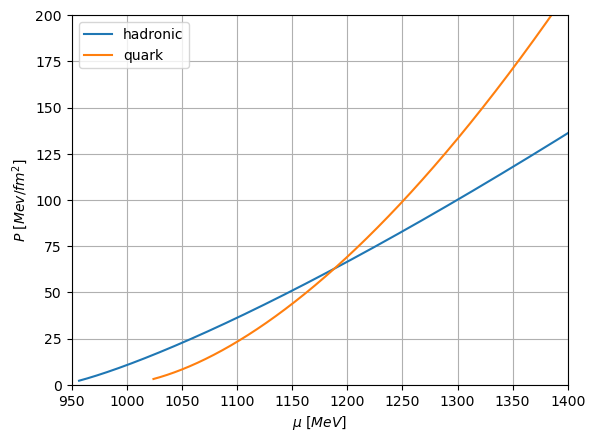

In [7]:
plt.plot(chemical_potential_had, pressure_had, label = "hadronic")
plt.plot(chemical_potential_quark,pressure_quark, label = "quark")

plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [8]:
mu_quark_new = []
for i in range(100):
    mu_quark_0 = (chemical_potential_quark - 50 + i)
    mu_quark_new.append(mu_quark_0)

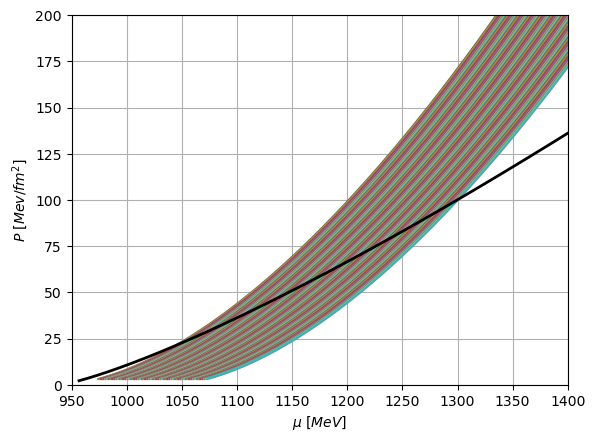

In [9]:
for i in range(len(mu_quark_new)):  # Assuming mu_quark_new is a list of lists
    plt.plot(mu_quark_new[i], pressure_quark, label=f"quark set {i+1}")

plt.plot(chemical_potential_had, pressure_had, label="hadronic", color='black', linewidth=2)  # Hadronic plot
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))  # Adjust legend position to handle many labels
plt.grid()
plt.show()

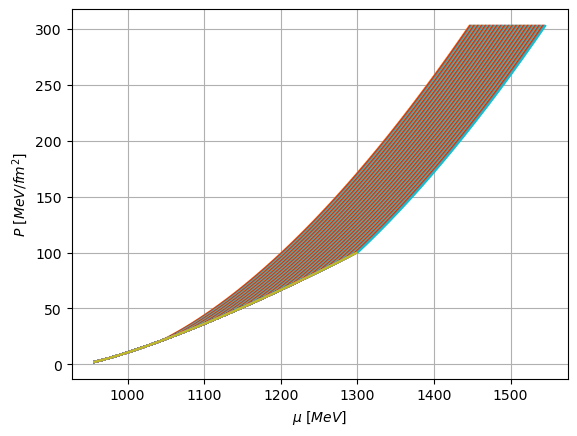

In [10]:
x1 = np.array(chemical_potential_had)
y1 = np.array(pressure_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# List to store combined curves for each quark phase
combined_mu_curves_quark, combined_mu_curves_had = [], []
combined_P_curves_quark, combined_P_curves_had = [], []
P_crit = []
mu_crit = []

combined_mu_curves, combined_p_curves = [], []
index_points =[]

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(pressure_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

    # Get the approximate intersection point
    x_intersect = mu_new[index_intersect]

    # Find the closest index in the original arrays to this intersection point
    index_had_closest = (np.abs(x1 - x_intersect)).argmin()
    index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

    index_points.append(index_had_closest)

    # Slice the original arrays at the closest intersection points
    mu_had_1 = x1[:index_had_closest]
    P_had = y1[:index_had_closest]
    mu_quark_2 = x2[index_quark_closest:]
    P_quark_2 = y2[index_quark_closest:]

    P_crit.append(P_quark_2[0])
    mu_crit.append(mu_quark_2[0])

    # Combine the original arrays at the intersection point
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    combined_mu_curves.append(combined_mu)
    combined_p_curves.append(combined_P)

    # Store the combined curves in the list
    combined_mu_curves_quark.append(mu_quark_2)
    combined_P_curves_quark.append(P_quark_2)

    # Store the combined curves in the list
    combined_mu_curves_had.append(mu_had_1)
    combined_P_curves_had.append(P_had)

# Plot the combined curves
for i in range(len(combined_mu_curves_had)):
    plt.plot(combined_mu_curves_had[i], combined_P_curves_had[i], label=f"Combined Curve {i+1}")
    plt.plot(combined_mu_curves_quark[i], combined_P_curves_quark[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Uncomment if legend is needed
plt.grid()
plt.show()


In [11]:
def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

In [12]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []
combined_cs2_11 = []
# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    # Compute the gradient of P with respect to mu
    gradient_1 = np.gradient(P_curve_1, mu_curve_1)
    gradient_2 = np.gradient(P_curve_2, mu_curve_2)

    e_curve_1 = (gradient_1*mu_curve_1)-P_curve_1
    cs2_1 = np.gradient(P_curve_1,e_curve_1)

    e_curve_2 = (gradient_2*mu_curve_2)-P_curve_2
    cs2_2 = np.gradient(P_curve_2,e_curve_2)

    P_curve_22 = np.linspace(P_curve_1[-1],P_curve_1[-1],10)
    mu_curve_22 = np.linspace(mu_curve_1[-1],mu_curve_1[-1],10)
    e_curve_22 = np.linspace(e_curve_1[-1],e_curve_2[0],10)
    cs2_22 = np.gradient(P_curve_22,e_curve_22)

    combined_n.append(np.concatenate((gradient_1,gradient_2)))
    combined_e.append(np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2.append(np.concatenate((cs2_1,cs2_22,cs2_2)))
    combined_p_1.append(np.concatenate((P_curve_1,P_curve_22,P_curve_2)))
    combined_mu_1.append(np.concatenate((mu_curve_1,mu_curve_22,mu_curve_2)))


    cs2_11 = np.gradient(np.concatenate((P_curve_1,P_curve_22,P_curve_2)),np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2_11.append(cs2_11)


/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1243: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1244: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1250: RuntimeWarning: invalid value encountered in add
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]


In [13]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []

# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    P_11 = np.concatenate((P_curve_1,P_curve_2))
    mu_11 = np.concatenate((mu_curve_1,mu_curve_2))

    gradient_11 = gradient(P_11, mu_11)
    e_11 = (gradient_11*mu_11[:-1])-P_11[:-1]
    combined_cs2.append(gradient(P_11[:-1],e_11))
    combined_n.append(gradient_11)
    combined_e.append(e_11)
    combined_p_1.append(P_11)
    combined_mu_1.append(mu_11)



def pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,n):
    for i in range(len(combined_cs2)):
        combined_mu_1[i]=np.delete(combined_mu_1[i],index_points[i]-n)
        combined_e[i]=np.delete(combined_e[i],index_points[i]-n)
        combined_p_1[i]=np.delete(combined_p_1[i],index_points[i]-n)
        combined_cs2[i]=np.delete(combined_cs2[i],index_points[i]-n)
    return()
    


In [14]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

In [15]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

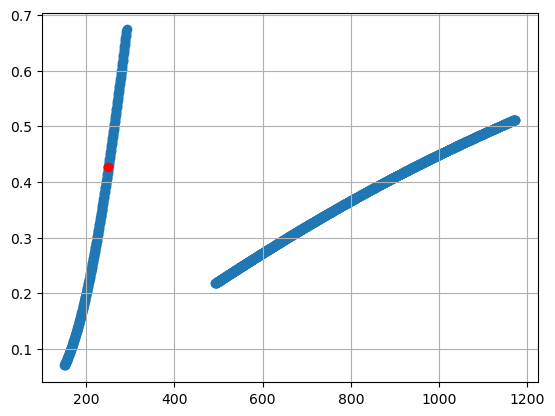

In [16]:
plt.scatter(combined_e[30][:-1],combined_cs2[30])
plt.scatter(combined_e[30][:-1][238],combined_cs2[30][238],color = 'red')
plt.grid()
plt.show()

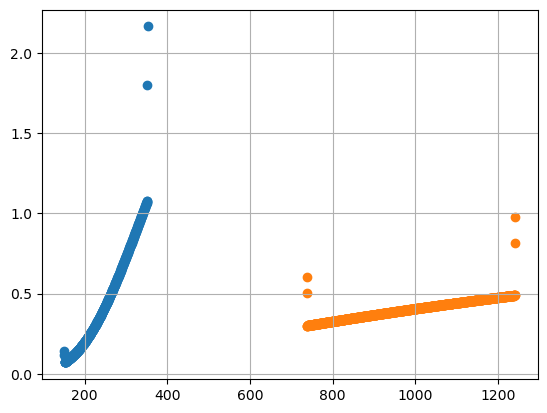

In [17]:
plt.scatter(e_curve_1,cs2_1)
plt.scatter(e_curve_2,cs2_2)
plt.grid()
plt.show()

In [18]:
mu_curve_1[-1]

1298.8498404772072

In [19]:
mu_curve_2[0]

1301.2786849161625

In [20]:
plt.scatter(mu_total[30],p_total[30]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

NameError: name 'mu_total' is not defined

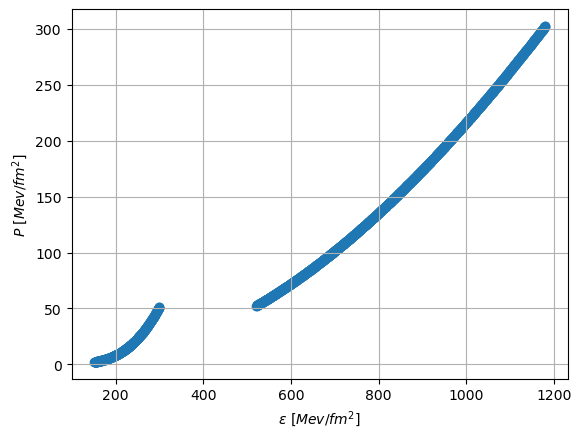

In [21]:
plt.scatter(combined_e[37],combined_p_1[37][:-1]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

In [22]:
e_total, p_total, mu_total, cs_total = combined_e, combined_p_1, combined_mu_1, combined_cs2

In [23]:
e_total

[array([ 151.08430517,  151.48634409,  151.88845752, ..., 1142.05196167,
        1142.65939714, 1143.26696617]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1143.05091115,
        1143.65876684, 1144.26675607]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1144.04986063,
        1144.65813653, 1145.26654597]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1145.04881011,
        1145.65750622, 1146.26633587]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1146.0477596 ,
        1146.65687591, 1147.26612578]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1147.04670908,
        1147.6562456 , 1148.26591568]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1148.04565856,
        1148.6556153 , 1149.26570558]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1149.04460804,
        1149.65498499, 1150.26549548]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1150.04355753,
        1150.65435468, 

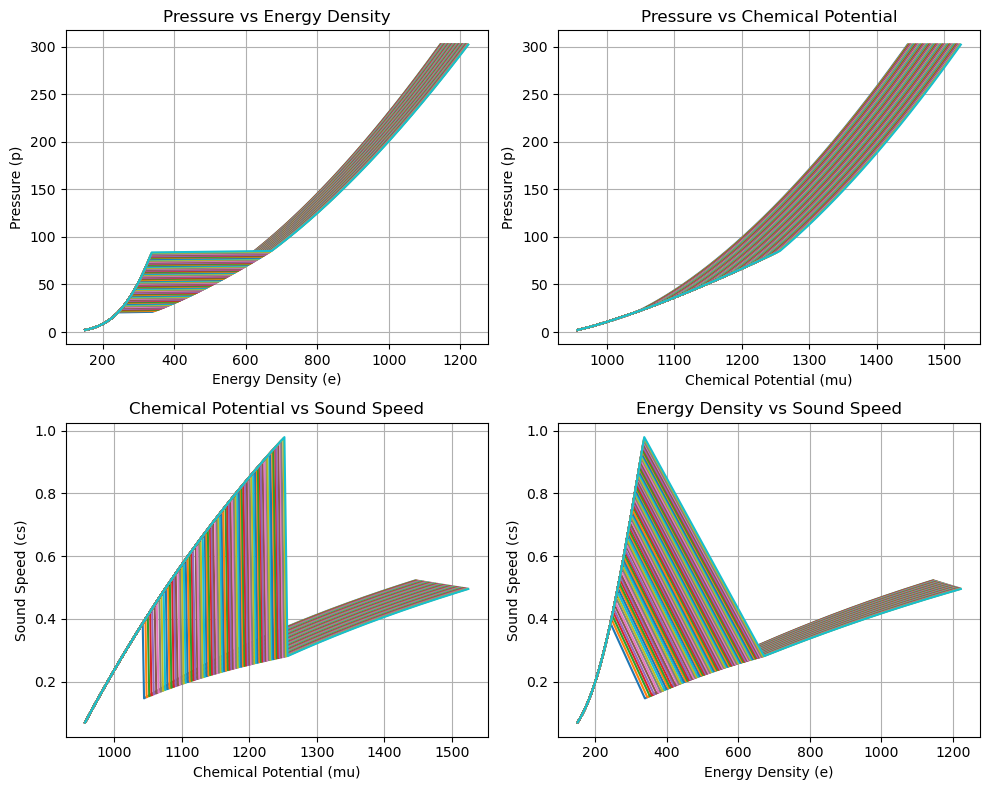

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i in range(len(p_total)-20):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i][:-1])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i][:-1], p_total[i][:-1])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i][:-2], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i][:-1], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [25]:
delta_P_optimal_1 = []
b_optimal_1 = []
a_optimal_1 = []
P_optimal_1 = []
min_distance_points_1 = []
min_distances_1 = []

P_all_max = []
# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)
    delta_P = np.linspace(P_crit[index]*0.01,P_crit[index]*0.3,1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    a_optimal_1.append(a_optimal)
    b_optimal_1.append(b_optimal)
    P_optimal_1.append(P_optimal)
    delta_P_optimal_1.append(delta_P_optimal)
    min_distance_points_1.append(min_distance_points)
    min_distances_1.append(min_distances)

In [26]:
len(P_optimal_1[1])

603

In [27]:
for i in range(len(P_optimal_1)):
    print(len(P_optimal_1[i]))

619
603
588
570
555
542
527
513
499
487
474
462
446
436
425
412
403
389
377
368
357
349
337
326
315
309
298
288
277
268
262
254
244
237
228
220
211
204
197
190
183
177
173
168
162
155
151
144
138
135
129
124
119
114
109
105
101
98
96
93
90
87
82
80
76
76
72
70
67
64
60
62
59
57
54
54
52
50
51
49
45
46
45
47
43
41
42
40
42
39
42
42
40
40
39
42
43
41
42
44


In [29]:
Del_p = [P_optimal_1[i][0] / P_crit[i] for i in range(len(P_optimal_1))]

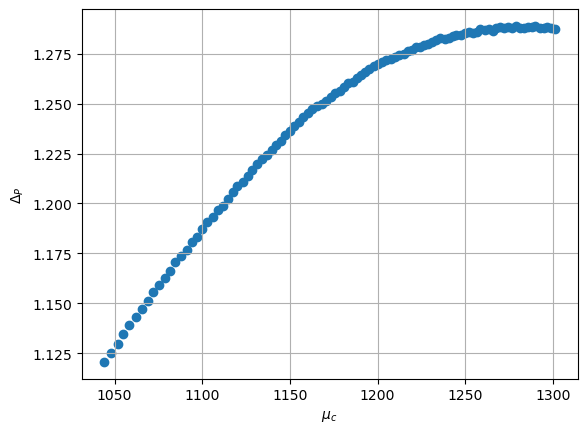

In [30]:
plt.scatter(mu_crit,Del_p);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta_{P} $');
plt.show();

In [25]:
# Lists to store results
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []
delta_P_Points = []
delta_P_optimal_max = []
P_all_max = []

# Store first values of a_opt and b_opt
a_opt_first_values = []
b_opt_first_values = []

# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index] * (1 + 0.01)
    P_crit_2 = P_crit[index] * (1 + 0.3)
    P_crit_new = np.linspace(P_crit_1, P_crit_2, 1000)
    delta_P = np.linspace(P_crit[index] * 0.01, P_crit[index] * 0.3, 1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index], P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue

    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    delta_P_optimal = np.array(delta_P_optimal)
    min_distance_points = np.array(min_distance_points)

    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index_min = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index_min])
        P_all_1.append(P_optimal[0])

        P_max_points.append(min_distance_points[index_min])
        P_max_points_1.append(min_distance_points[0])
        delta_P_Points.append(delta_P_optimal[0])
        delta_P_optimal_max.append(delta_P_optimal[-1])
        P_all_max.append(P_optimal[-1])

        # Save the first values of a_opt and b_opt
        a_opt_first_values.append(a_optimal[0])
        b_opt_first_values.append(b_optimal[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)
        a_opt_first_values.append(0)
        b_opt_first_values.append(0)

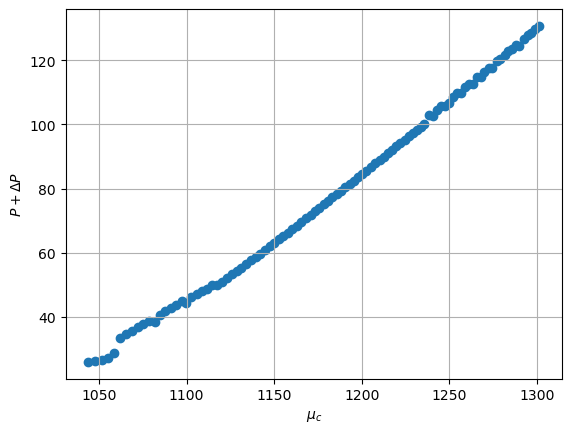

In [26]:
plt.scatter(mu_crit,P_all);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

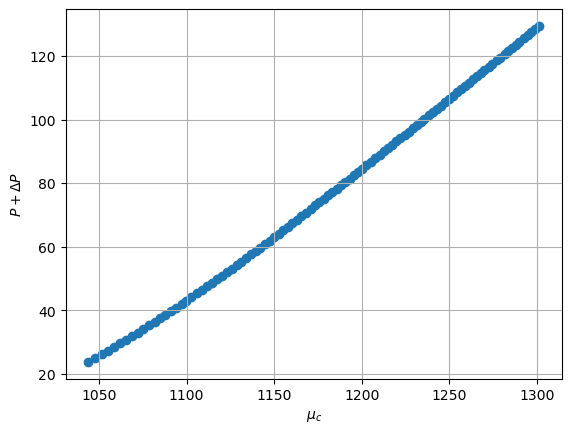

In [27]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [29]:
del_p = np.array(delta_P_Points)/np.array(P_crit)

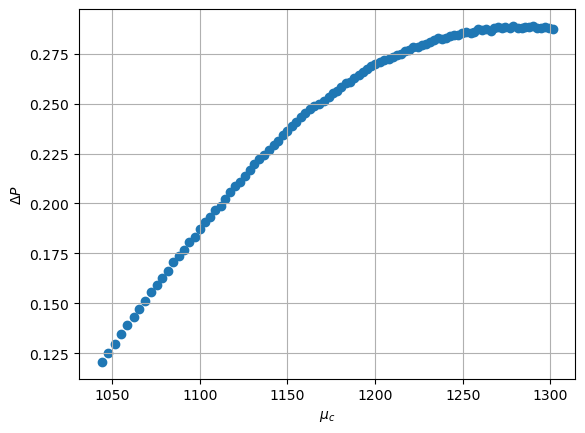

In [30]:
plt.scatter(mu_crit,del_p);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

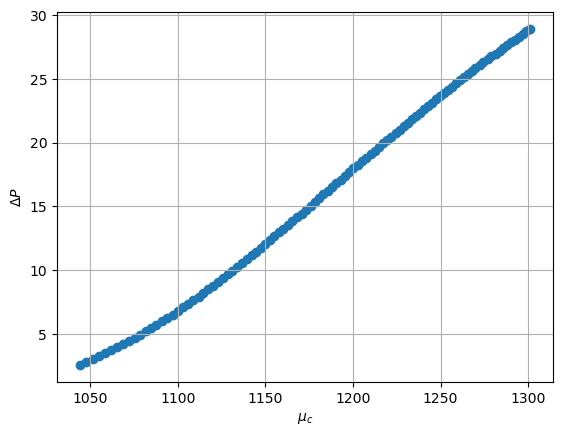

In [65]:
plt.scatter(mu_crit,delta_P_Points);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

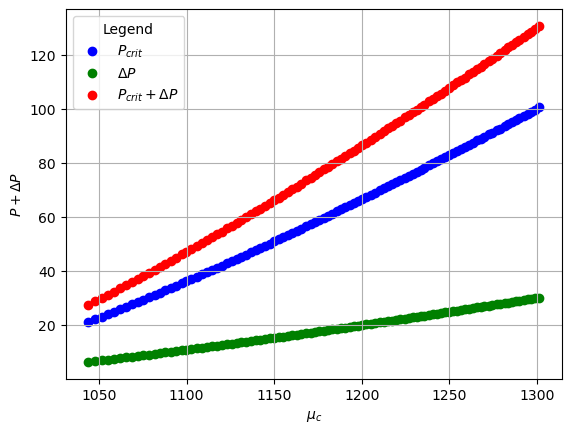

In [66]:
# Plotting the scatter points
plt.scatter(mu_crit, P_crit, label=r"$P_{crit}$", color='b')
plt.scatter(mu_crit, delta_P_optimal_max, label=r"$\Delta P$", color='g')
plt.scatter(mu_crit, P_all_max, label=r"$P_{crit} + \Delta P$", color='r')

# Adding grid, labels, and legend
plt.grid()
plt.xlabel(r'$\mu_c$')
plt.ylabel(r'$P + \Delta P$')

# Display the legend to label the lines
plt.legend(title='Legend', loc='best')

# Show the plot
plt.show()


In [67]:
len(delta_P_optimal_max)

100

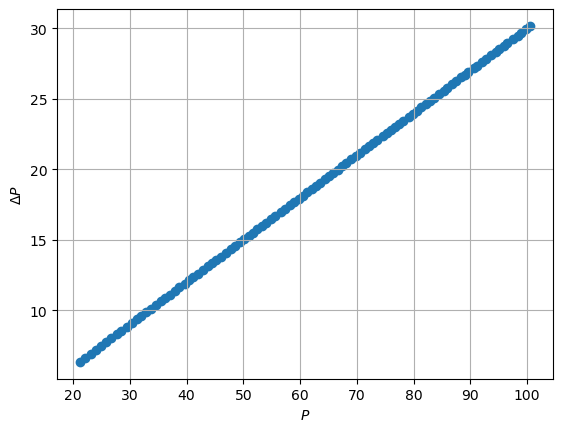

In [68]:
plt.scatter(P_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$P$');
plt.ylabel(r'$\Delta P $');
plt.show();

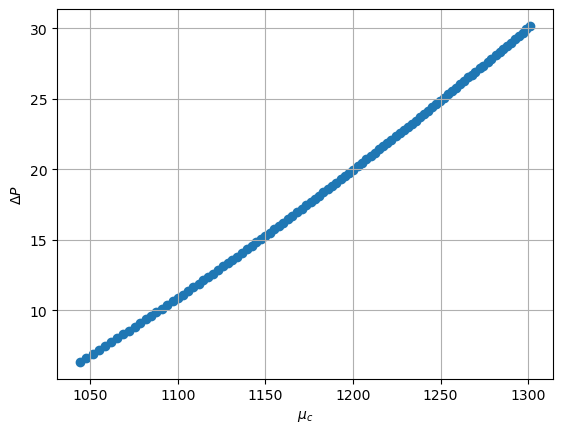

In [69]:
plt.scatter(mu_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

 Curve Fit

In [70]:
def quadratic_fit(x, y):
    """
    Fit a quadratic curve to the given data points (x, y).

    Parameters:
        x (array-like): The input data points for the x-axis.
        y (array-like): The input data points for the y-axis.

    Returns:
        tuple: A tuple containing:
            - coefficients (a, b, c) for the quadratic curve y = ax^2 + bx + c
            - a function to compute fitted y-values for any input x.
    """
    # Perform quadratic curve fitting
    coefficients = np.polyfit(x, y, deg=2)  # Returns [a, b, c] for y = ax^2 + bx + c
    
    # Create a function for the fitted curve
    def fitted_curve(x_values):
        return coefficients[0] * x_values**2 + coefficients[1] * x_values + coefficients[2]
    
    return coefficients, fitted_curve

Quadratic Coefficients (a, b, c): [ 2.32346317e-04 -1.26596657e-01 -9.84430413e+01]
Fitted values at mu_crit: [ 22.6266107   23.99716644  25.3836617   26.57708505  27.8517778
  29.21028803  30.43874025  31.67816046  32.85492178  34.11559287
  35.31214945  36.51828255  37.58087638  38.80477061  40.03832634
  41.12420927  42.37568546  43.39682121  44.50430882  45.70006264
  46.82226612  48.03410796  49.08790519  50.14759307  51.21318628
  52.45466297  53.53328061  54.61785085  55.6216176   56.71754832
  57.90742593  59.0159555   60.04137501  61.16137872  62.19717045
  63.23789844  64.28357362  65.33420696  66.38980944  67.45039204
  68.51596576  69.58654162  70.75672462  71.83788435  72.92408064
  73.91908733  75.01483964  76.0183849   77.025968    78.13585127
  79.15202412  80.17225882  81.19656305  82.22494449  83.25741081
  84.2939697   85.33462885  86.37939595  87.53105507  88.58456164
  89.64220028  90.70397872  91.66512019  92.73469672  93.70270621
  94.88634318  95.86168544  96.94

<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_14754/129519629.py:21: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(mu_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\mu^2 + {coeffs[1]:.2f}\mu + {coeffs[2]:.2f}$', zorder=2)
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_14754/129519629.py:21: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(mu_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\mu^2 + {coeffs[1]:.2f}\mu + {coeffs[2]:.2f}$', zorder=2)


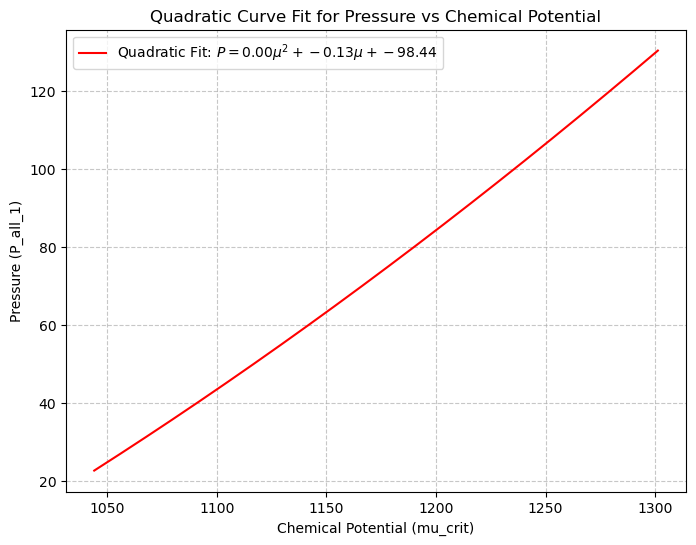

In [71]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure mu_crit and P_all_1 are NumPy arrays
mu_crit = np.array(mu_crit)  # Convert to NumPy array if it's a list
P_all_1 = np.array(P_all_1)  # Convert to NumPy array if it's a list

# Get quadratic fit
coeffs, fit_fn = quadratic_fit(mu_crit, P_all_1)

print("Quadratic Coefficients (a, b, c):", coeffs)
print("Fitted values at mu_crit:", fit_fn(mu_crit))

# Generate points for the fitted curve
mu_fine = np.linspace(min(mu_crit), max(mu_crit), 500)  # Fine-grained x values for a smooth curve
P_fitted = fit_fn(mu_fine)

# Plot the original data and the fitted curve
plt.figure(figsize=(8, 6))
#plt.scatter(mu_crit, P_all_1, color='blue', label='Original Data', zorder=3)
plt.plot(mu_fine, P_fitted, color='red', label=f'Quadratic Fit: $P = {coeffs[0]:.2f}\mu^2 + {coeffs[1]:.2f}\mu + {coeffs[2]:.2f}$', zorder=2)
plt.xlabel('Chemical Potential (mu_crit)')
plt.ylabel('Pressure (P_all_1)')
plt.title('Quadratic Curve Fit for Pressure vs Chemical Potential')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

M-R Curve

In [74]:
import numpy as np
from numba import jit
import time
from scipy.interpolate import interp1d

G=1
c=1
M01 = 1.474 * 10**3

G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
c1 = 3*10**(8)                  ############ m / s

Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4


from numba import jit
#@jit(nopython = True)
def love_number(C,y):
  k2 = 8 / 5 * C ** 5 * (1 - 2 * C) **(2) * (2 + 2 * C * (y - 1) - y) * (2 * C * (6 - 3 * y + 3 * C * (5 * y - 8)) + 4 * C ** 3 * (13 - 11 * y + C * (3 * y - 2) + 2 * C ** 2 * (1 + y)) + 3 * (1 - 2 * C) ** 2 * (2 - y + 2 * C * (y - 1)) * (np.log(1 - 2 * C))) ** (-1)
  return k2


#@jit(nopython = True)
def beta_and_H(r, p, H, m, beta, parr, earr):
    dp = p * 0.005

    el_3 = en_dens(parr, earr, p - 3 * dp)
    el_2 = en_dens(parr, earr, p - 2 * dp)
    el_1 = en_dens(parr, earr, p - 1 * dp)
    er_3 = en_dens(parr, earr, p + 3 * dp)
    er_2 = en_dens(parr, earr, p + 2 * dp)
    er_1 = en_dens(parr, earr, p + 1 * dp)

    de_dp = (-1 / 60 * el_3 + 3 / 20 * el_2 - 3 / 4 * el_1 + 3 / 4 * er_1 - 3 / 20 * er_2 + 1 / 60 * er_3) / dp

    #G = 6.67430e-11  # Gravitational constant
    #c = 299792458.0  # Speed of light
    G = 1
    c = 1

    e = en_dens(parr, earr, p)
    dbeta_dr = 2 * (1 - 2 * m / r ) ** (-1) *H * (-2 * np.pi * G / c ** 2 * (5 * e + 9 * p / c ** 2 + de_dp * c ** 2 * (e + p / c ** 2)) + 3 / r ** 2 + 2 * (1 - 2 * m / r ) ** (-1) * ( m / r ** 2 + G / c ** 4 * 4 * np.pi * r * p) ** 2) + 2 * (1 - 2 * m / r ) ** (-1) *beta / r * (-1 + m / r + 2 * np.pi * r ** 2 * G / c ** 2 * (e - p / c ** 2))

    dHdr = beta
    return dbeta_dr, dHdr

@jit(nopython = True)
def en_dens(parr, earr, p):
  if p < min(parr) or p > max(parr):
    e = 0
  else:
    e = ene_interp(parr, earr, p)
  return e

@jit(nopython = True)
def find_ind(arr, val):
    for i, item in enumerate(arr):
        if val > item:
            continue
        else:
            return i
    return len(arr)

class PressureOutOfRangeError(Exception):
    pass

@jit(nopython = True)
def en_dens(parr, earr, p):
  if p < min(parr) or p > max(parr):
    e = 0
  else:
    e = ene_interp(parr, earr, p)
  return e


@jit(nopython = True)
def ene_interp(pre_arr, ene_arr, pressure):
    if pressure < min(pre_arr) or pressure > max(pre_arr):
        raise PressureOutOfRangeError("Pressure is out of range.")
    else:
        ind = find_ind(pre_arr, pressure)
        left_p = pre_arr[ind - 1]
        right_p = pre_arr[ind]
        left_e = ene_arr[ind-1]
        right_e = ene_arr[ind]
        ene_val = (pressure - left_p)*(right_e - left_e)/(right_p - left_p) + left_e
    return ene_val

@jit(nopython = True)
def pre_interp(pre_arr, ene_arr, energy):
    if energy < min(ene_arr) or energy > max(ene_arr):
        raise PressureOutOfRangeError("Energy is out of range.")
    else:
        ind = find_ind(ene_arr, energy)
        left_p = pre_arr[ind - 1]
        right_p = pre_arr[ind]
        left_e = ene_arr[ind-1]
        right_e = ene_arr[ind]
        pre_val = (energy - left_e)*(right_p - left_p)/(right_e - left_e) + left_p
    return pre_val

def cs2_interp(cs2_arr, pre_arr, pressure):
    if pressure < min(pre_arr) or pressure > max(pre_arr):
        raise PressureOutOfRangeError("Pressure is out of range.")
    else:
        ind = find_ind(pre_arr, pressure)
        left_c = cs2_arr[ind - 1]
        right_c = cs2_arr[ind]
        left_p = pre_arr[ind-1]
        right_p = pre_arr[ind]
        cs2_val = (pressure - left_p)*(right_c - left_c)/(right_p - left_p) + left_c
    return cs2_val

@jit(nopython = True)
def Tov_eqn(P, r, m, dens, press, G, c, min_pressure):
    if P < min_pressure:
        return 0.0
    else:
        eden = ene_interp(press, dens, P)
        return -(G * ((P / c ** 2) + eden) * (m + 4 * np.pi * r ** 3 * P / c ** 2)) / (r * (r - 2 * G * m / c ** 2))

@jit(nopython = True)
def mass_eqn(r, ene):
    return 4 * np.pi * r ** 2 * ene


def TOV_module(cen_dens, pressure, density, exit_Pre,love=False, to_print=False):
    asi = 0
    P_exit =exit_Pre
    for i in range(len(cen_dens)):
        press = np.array(pressure)
        dens = np.array(density)
        d = cen_dens[i]
        P0 = pre_interp(press, dens, d)
        r = 10
        P = P0
        m = mass_eqn(r,d)
        h = 1
        a0 = 1
        H0 = a0*r**2
        beta0 = 2*a0*r
        min_pressure = min(press)
        beta = beta0
        H = H0
        if  love == True:
            #print("Entering Love loop")
            while P > P_exit :
                k1_m = mass_eqn(r, ene_interp(press, dens, P))
                k2_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k3_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k4_m = mass_eqn(r + h, ene_interp(press, dens, P))

                k1_p = Tov_eqn(P, r, m, dens, press, G, c, min_pressure)
                k2_p = Tov_eqn(P + k1_p * h / 2, r + h / 2, m + k1_m * h / 2, dens, press, G, c, min_pressure)
                k3_p = Tov_eqn(P + k2_p * h / 2, r + h / 2, m + k2_m * h / 2, dens, press, G, c, min_pressure)
                k4_p = Tov_eqn(P + k3_p * h, r + h, m + k3_m * h, dens, press, G, c, min_pressure)

                k1_dbeta_dr, k1_dHdr = beta_and_H(r, P, H, m, beta, press, dens)
                k2_dbeta_dr, k2_dHdr = beta_and_H(r + 0.5 * h, P + 0.5 * h * k1_p, H + 0.5 * h * k1_dHdr, m + 0.5*h*k1_m, beta + 0.5*h*k1_dbeta_dr, press, dens)
                k3_dbeta_dr, k3_dHdr = beta_and_H(r + 0.5 * h, P + 0.5 * h * k2_p, H + 0.5 * h * k2_dHdr, m + 0.5*h*k2_m, beta + 0.5*h*k2_dbeta_dr, press, dens)
                k4_dbeta_dr, k4_dHdr = beta_and_H(r + h, P + h * k3_p, H + h * k3_dHdr, m + h*k3_m, beta + h*k3_dbeta_dr, press, dens)

                beta = beta + (h / 6.0) * (k1_dbeta_dr + 2 * k2_dbeta_dr + 2 * k3_dbeta_dr + k4_dbeta_dr)
                H = H + (h / 6.0) * (k1_dHdr + 2 * k2_dHdr + 2 * k3_dHdr + k4_dHdr)
                P += h * (k1_p + 2 * k2_p + 2 * k3_p + k4_p) / 6
                m += h * (k1_m + 2 * k2_m + 2 * k3_m + k4_m) / 6
                r += h
            R.append(r/1000)
            M.append(m/M01)
            y = r * beta/ (H)
            C = m/r
            k2 = love_number(C,y)
            Com.append(C)
            Love.append(k2)
            if to_print == True:
                print("star ", i," done")
        else:
            #print("Entering No Love loop")
            while P > P_exit :
                k1_m = mass_eqn(r, ene_interp(press, dens, P))
                k2_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k3_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k4_m = mass_eqn(r + h, ene_interp(press, dens, P))

                k1_p = Tov_eqn(P, r, m, dens, press, G, c, min_pressure)
                k2_p = Tov_eqn(P + k1_p * h / 2, r + h / 2, m + k1_m * h / 2, dens, press, G, c, min_pressure)
                k3_p = Tov_eqn(P + k2_p * h / 2, r + h / 2, m + k2_m * h / 2, dens, press, G, c, min_pressure)
                k4_p = Tov_eqn(P + k3_p * h, r + h, m + k3_m * h, dens, press, G, c, min_pressure)

                P += h * (k1_p + 2 * k2_p + 2 * k3_p + k4_p) / 6
                m += h * (k1_m + 2 * k2_m + 2 * k3_m + k4_m) / 6
                r += h
            R.append(r/1000)
            M.append(m/M01)
            #if to_print == True:
                #print("star ", i," done")
    return R,M,Com,Love

In [75]:
G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
c1 = 3*10**(8)                  ############ m / s

Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4

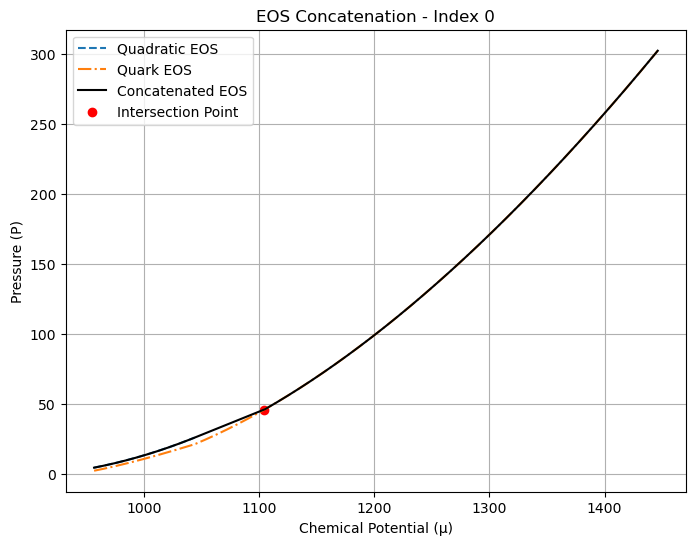

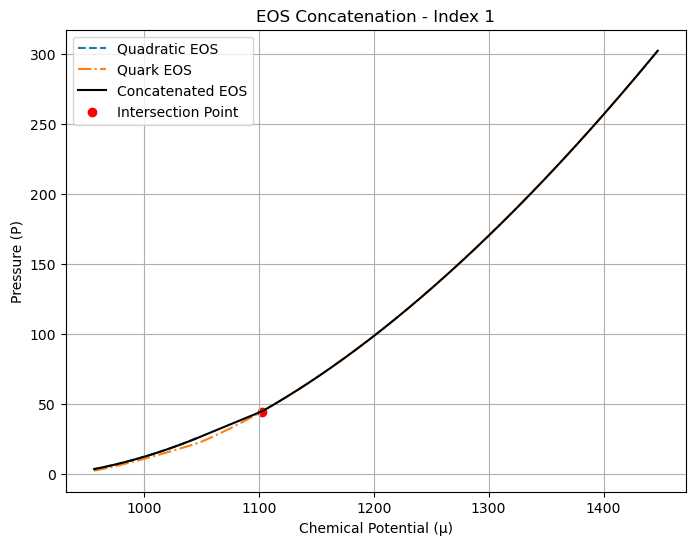

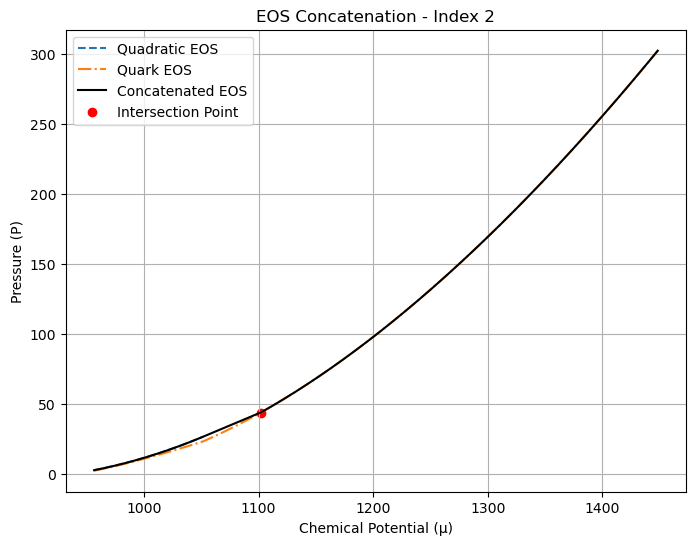

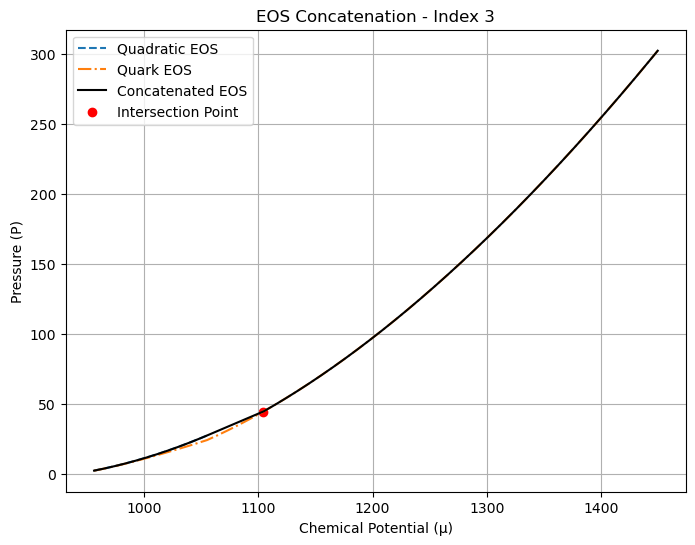

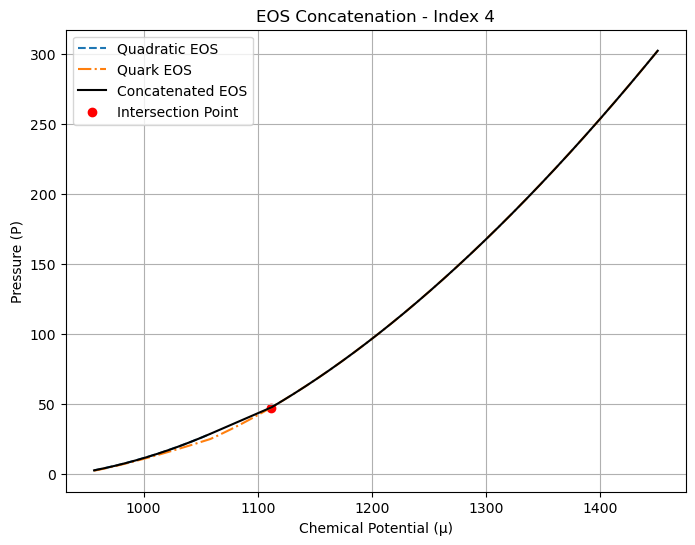

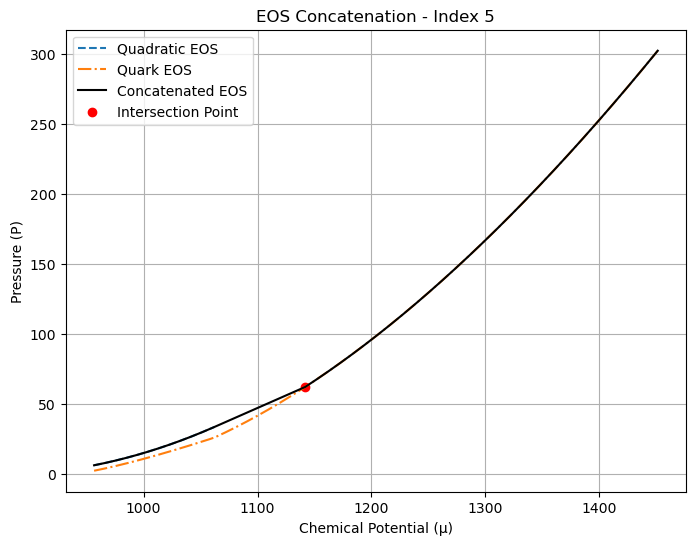

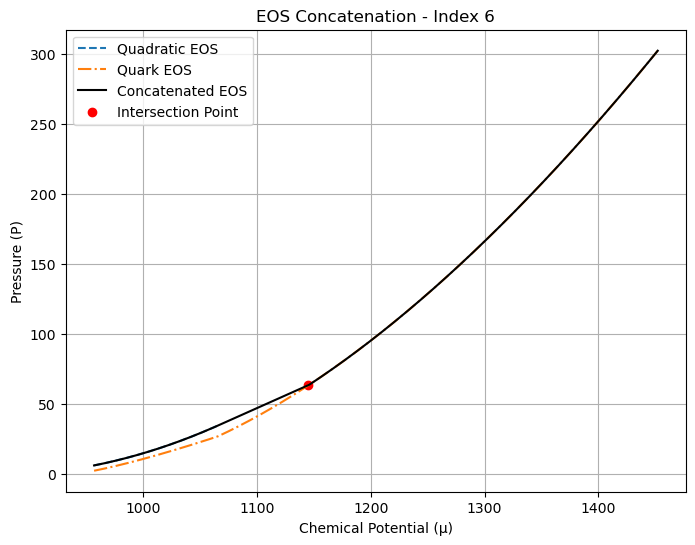

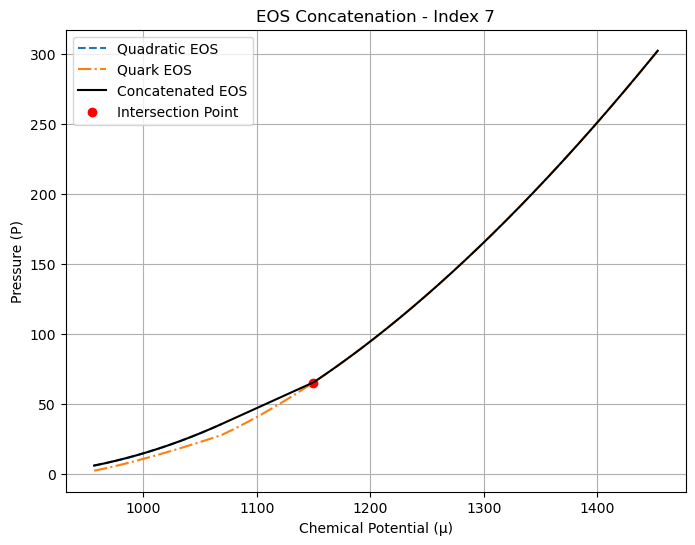

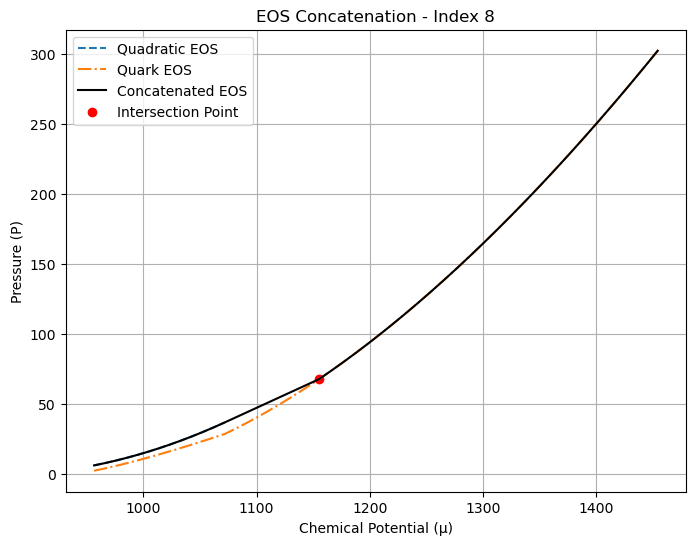

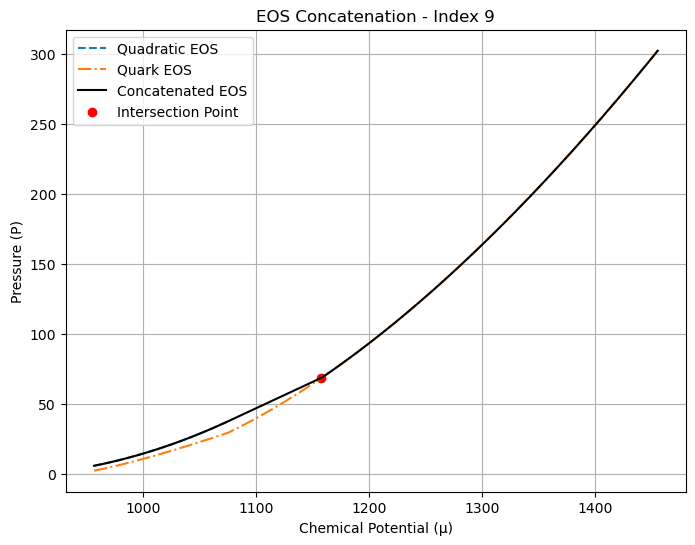

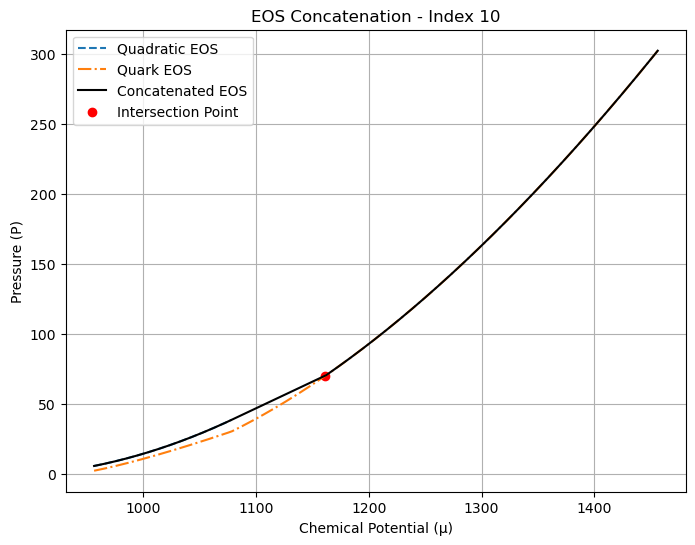

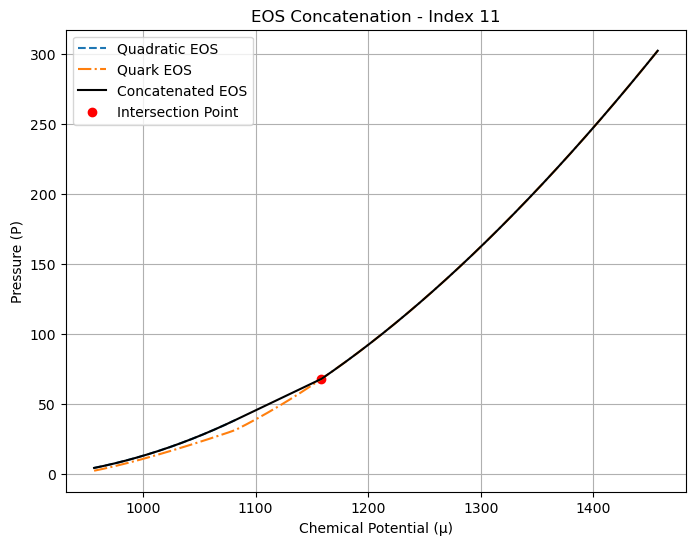

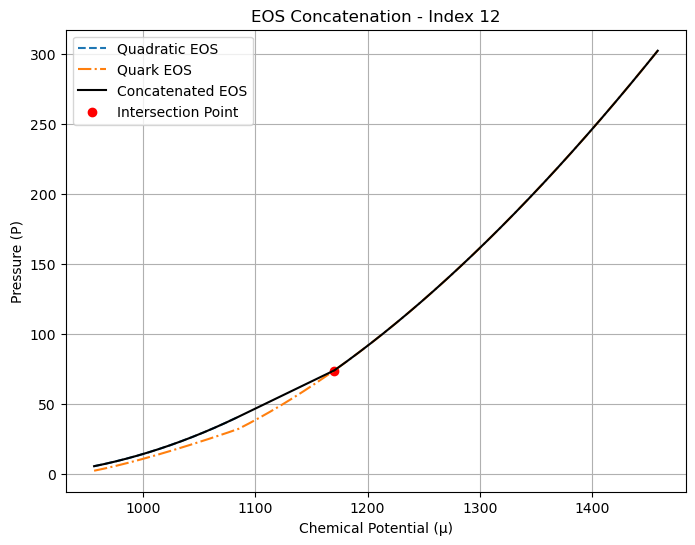

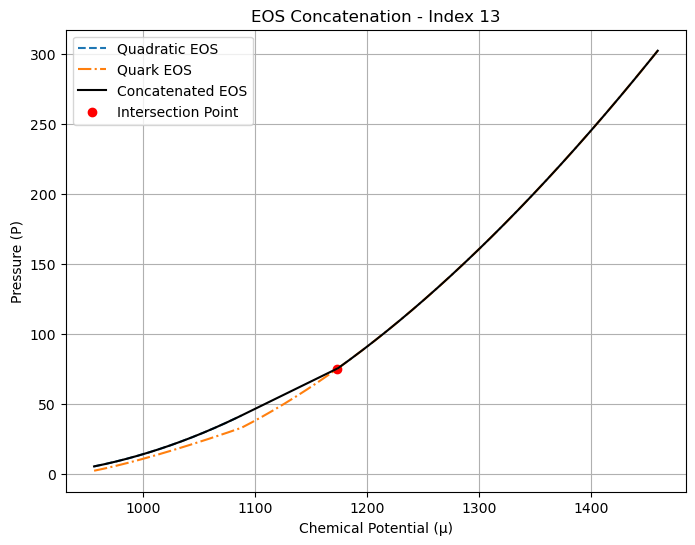

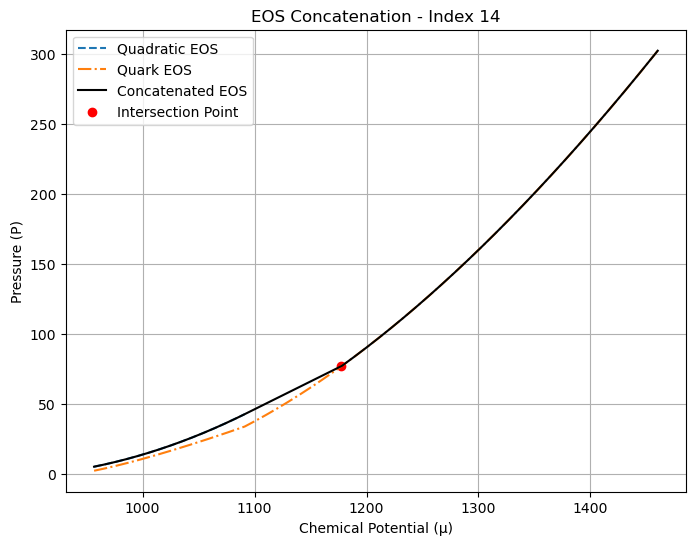

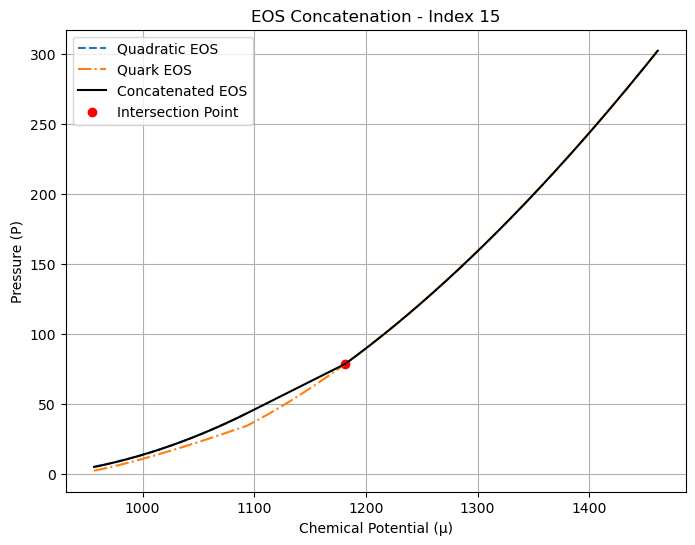

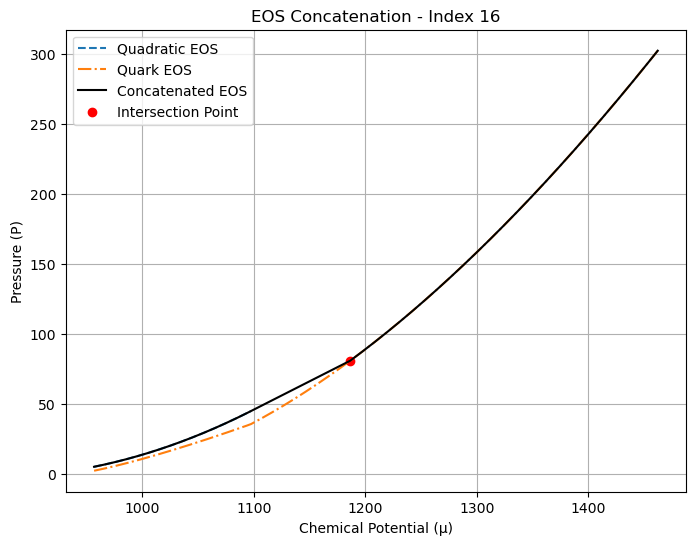

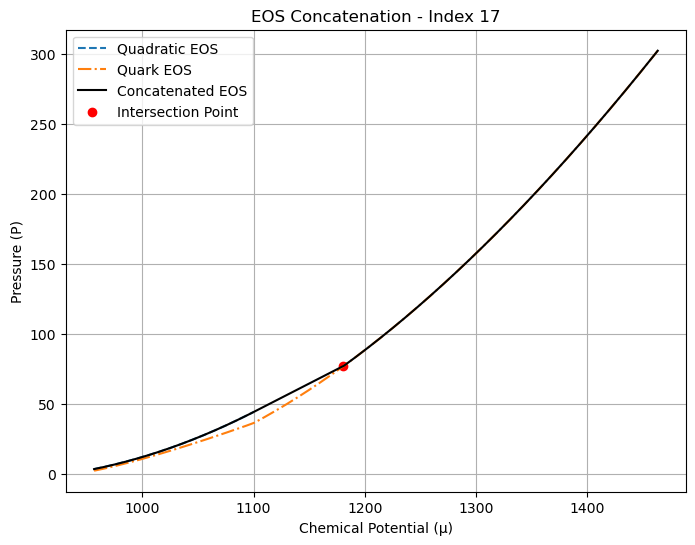

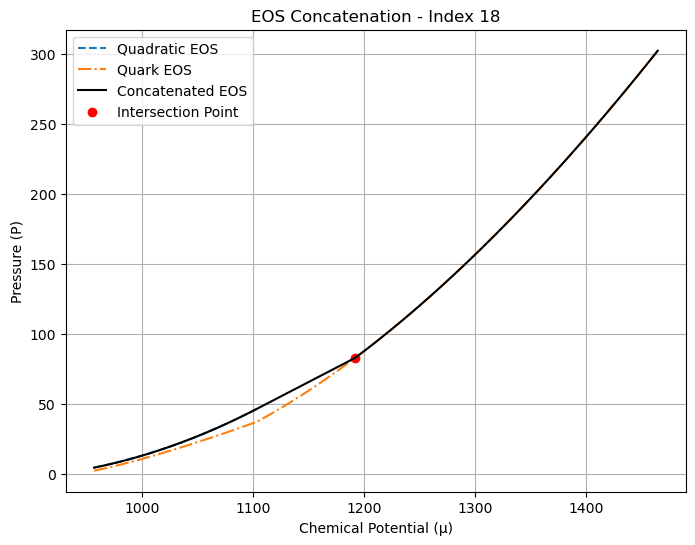

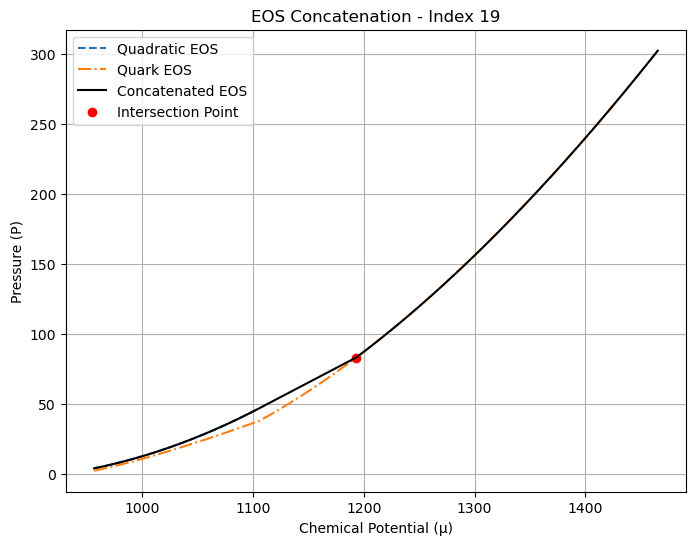

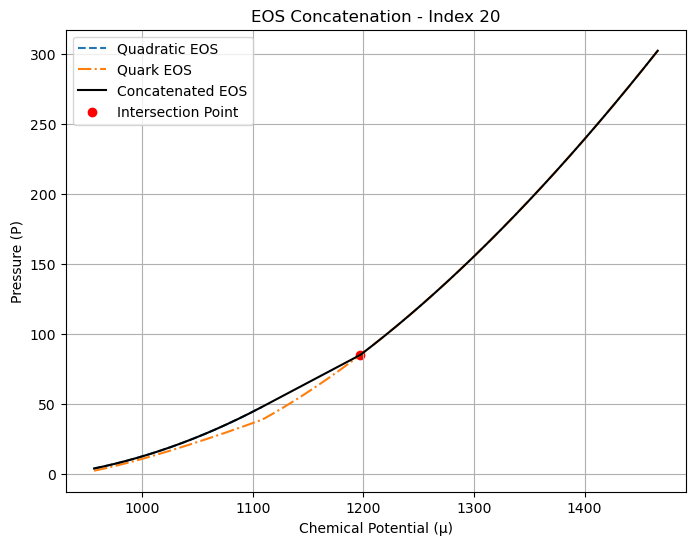

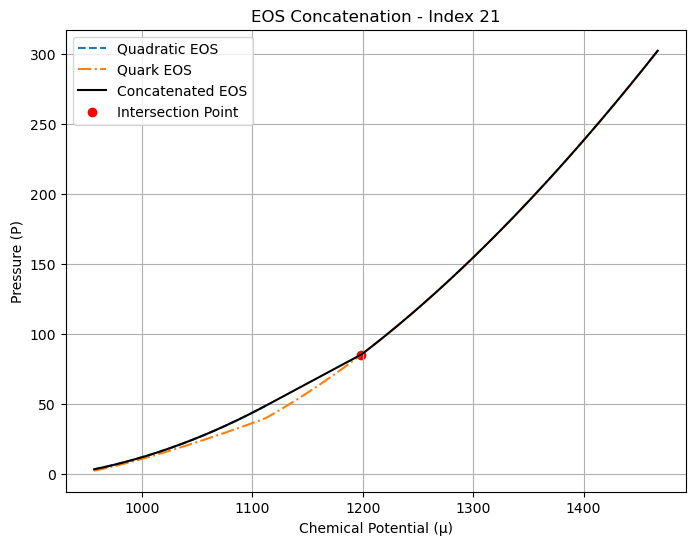

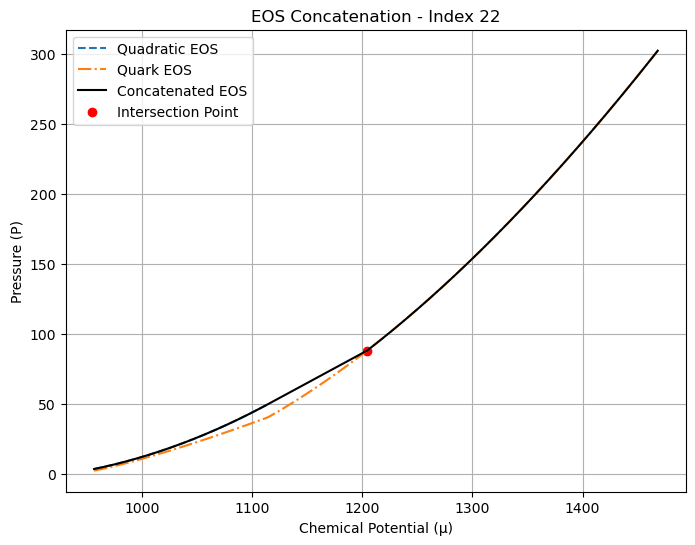

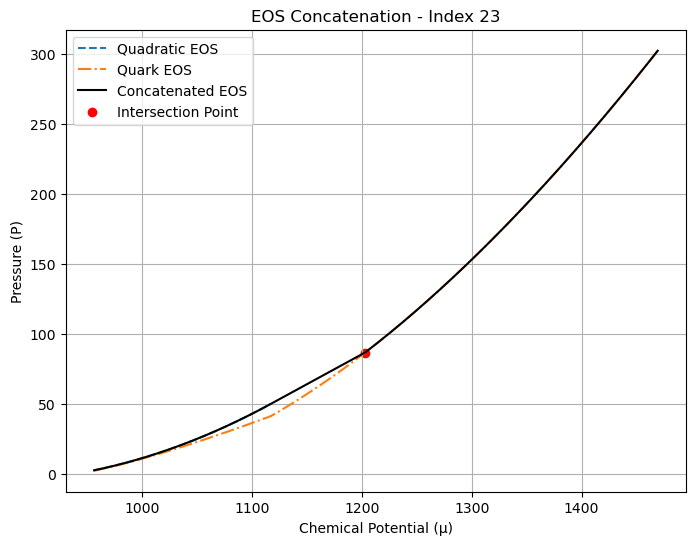

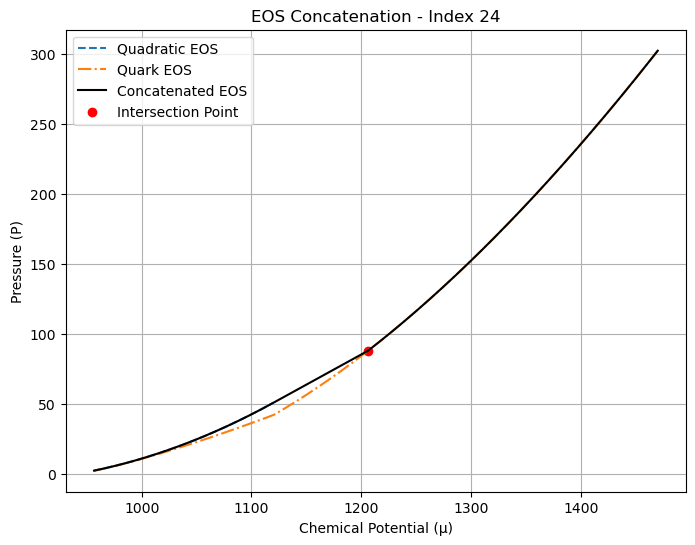

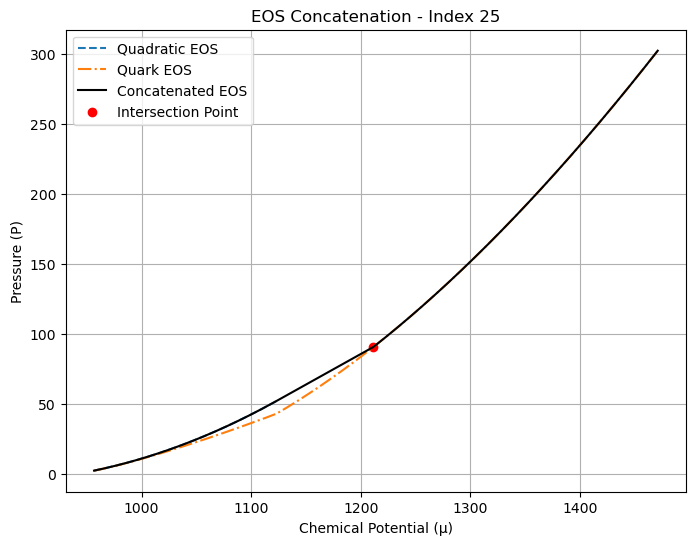

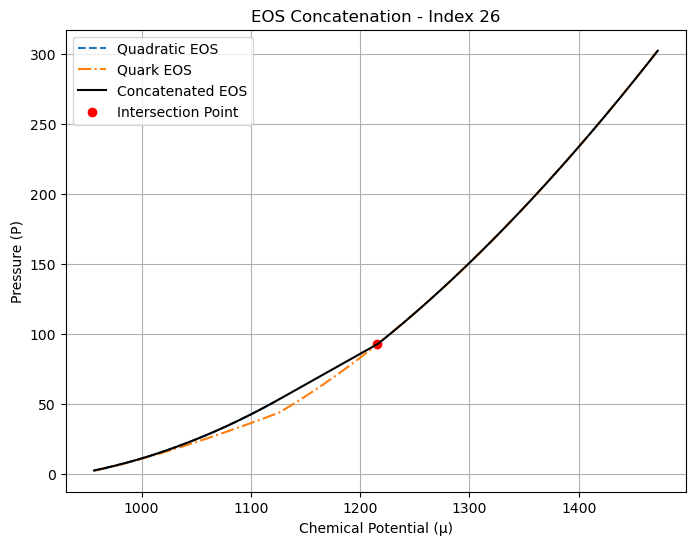

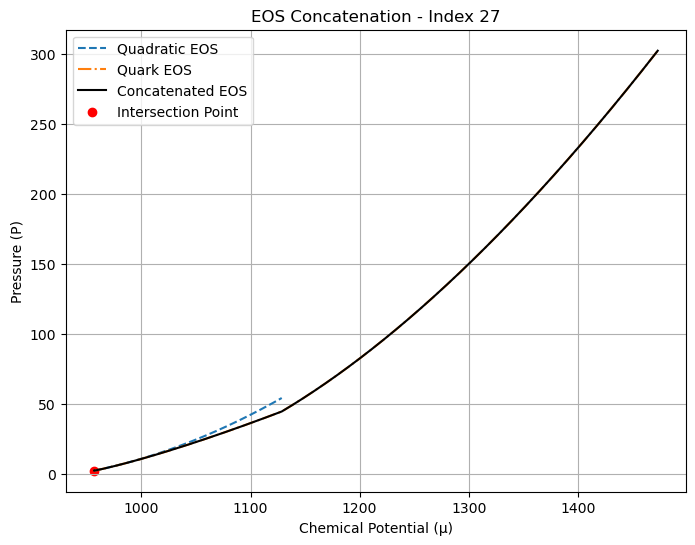

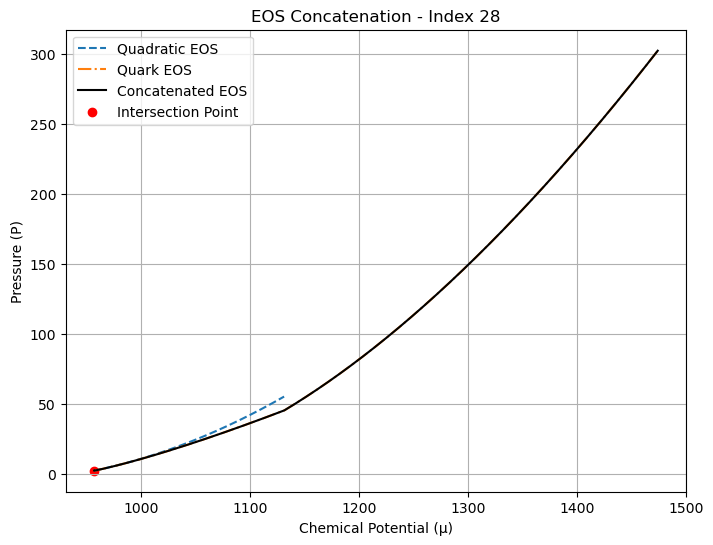

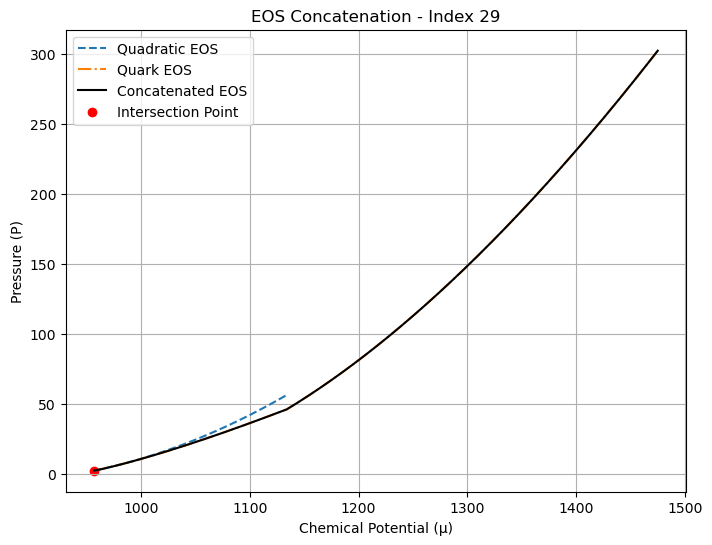

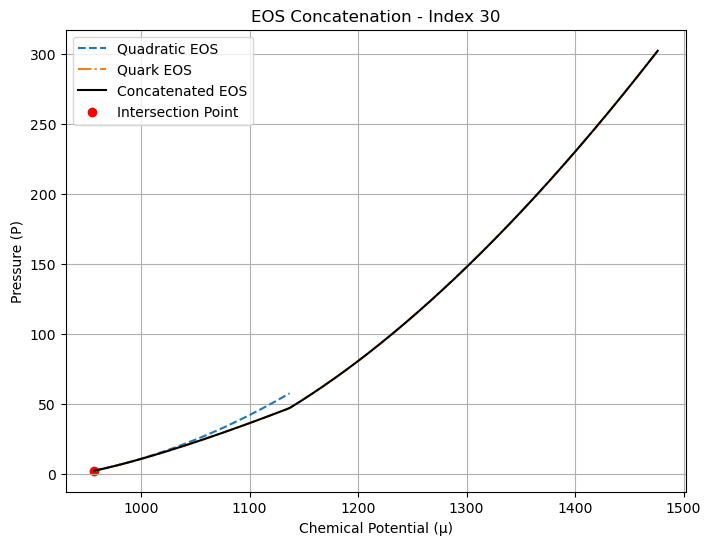

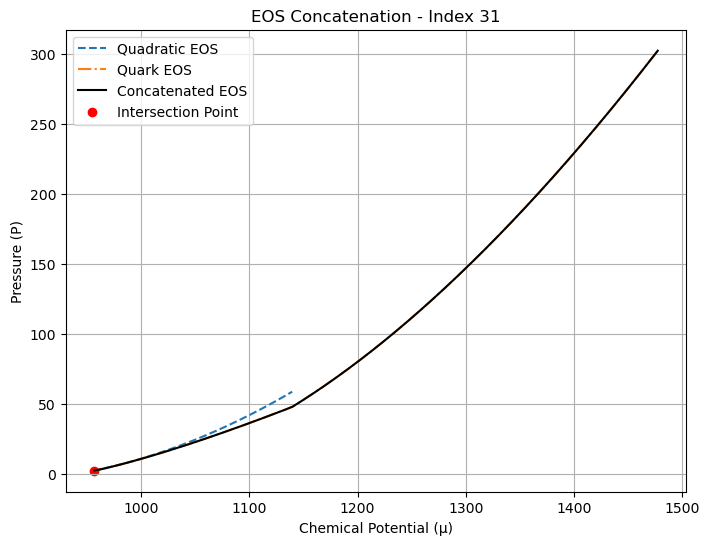

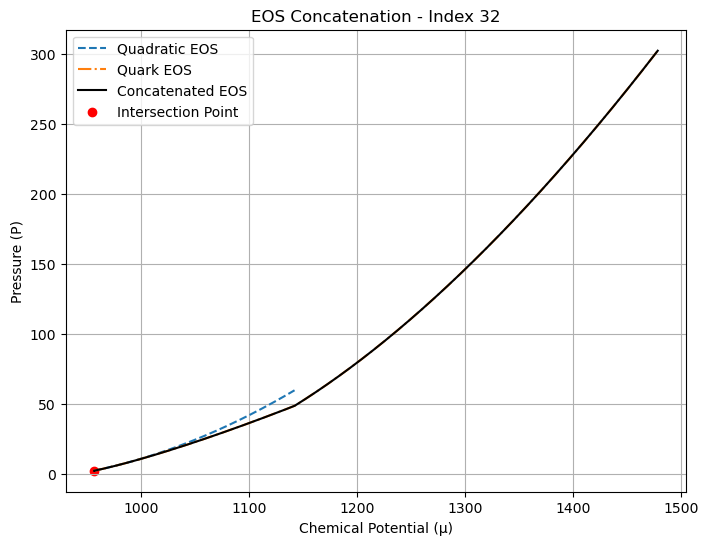

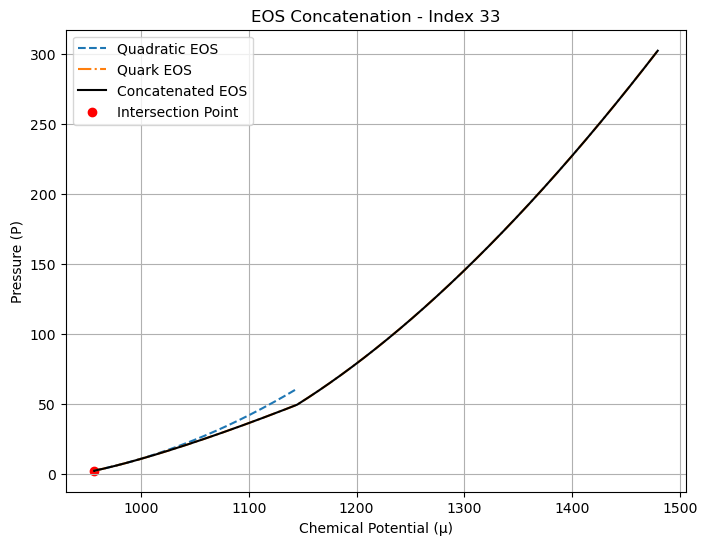

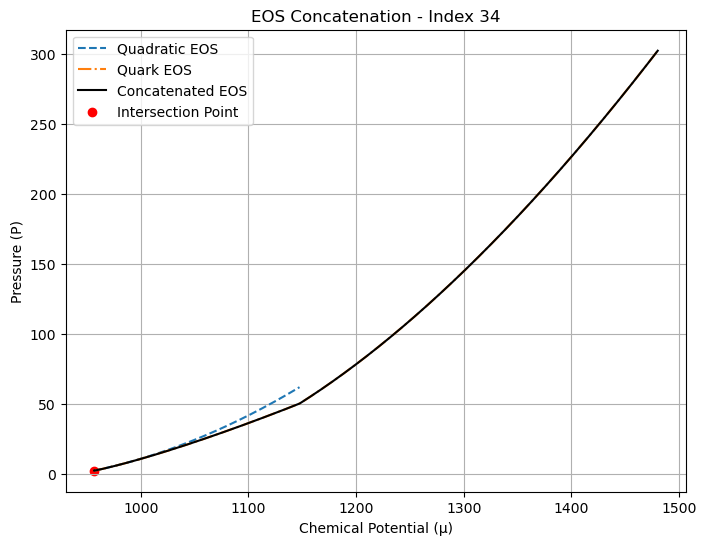

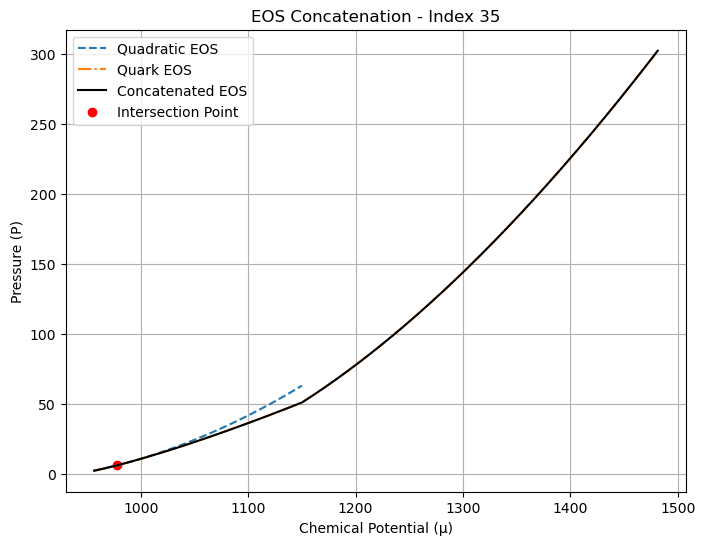

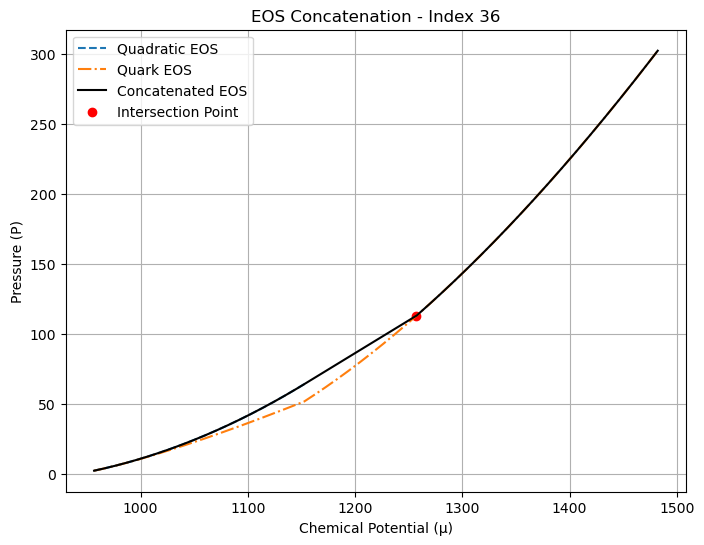

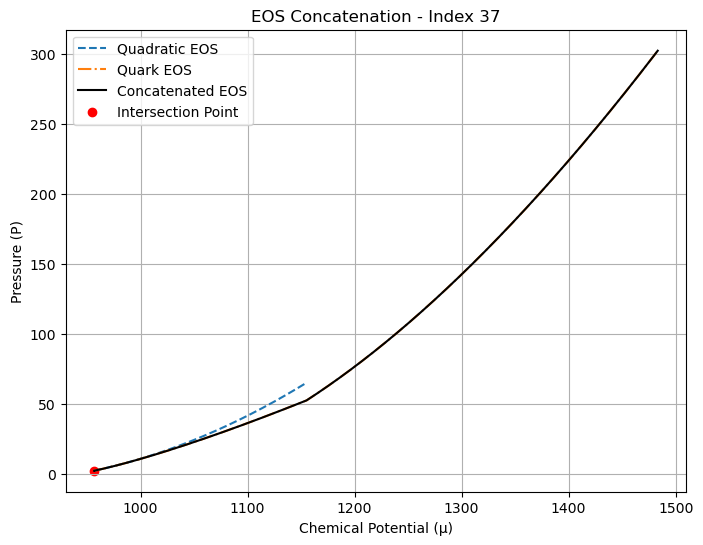

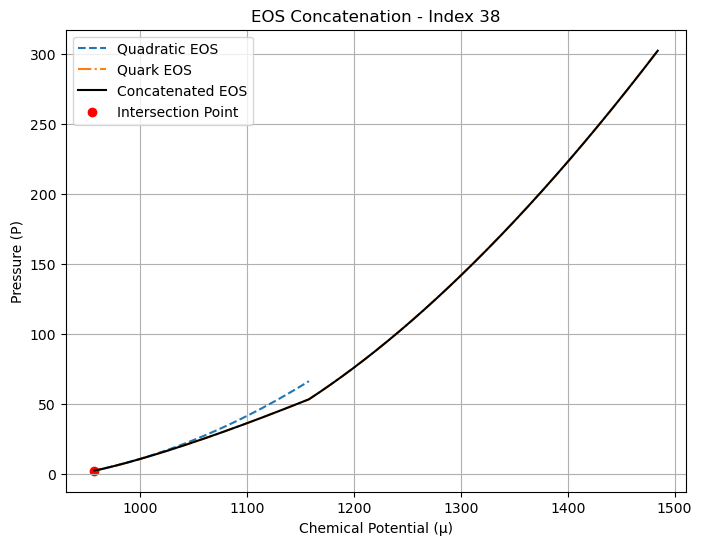

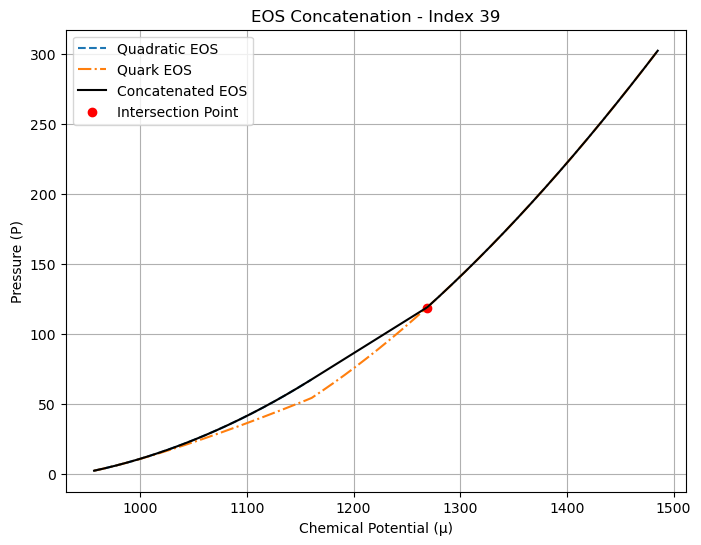

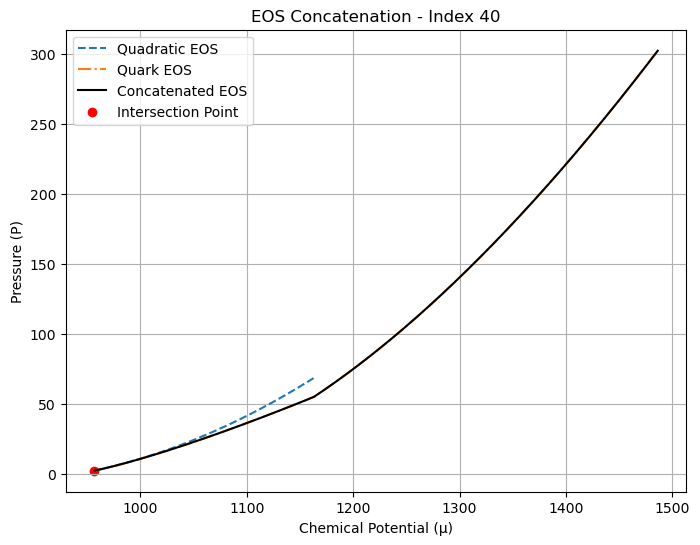

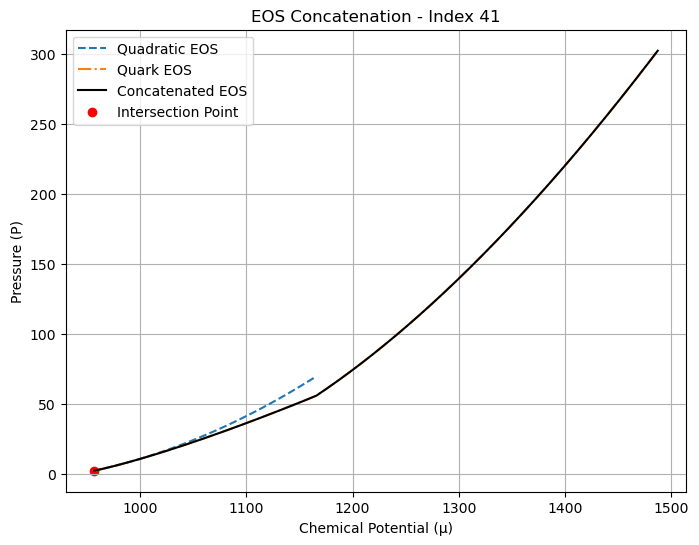

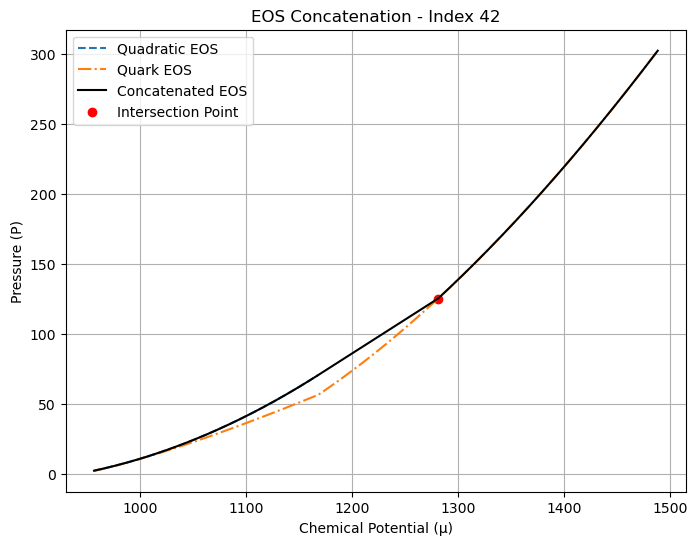

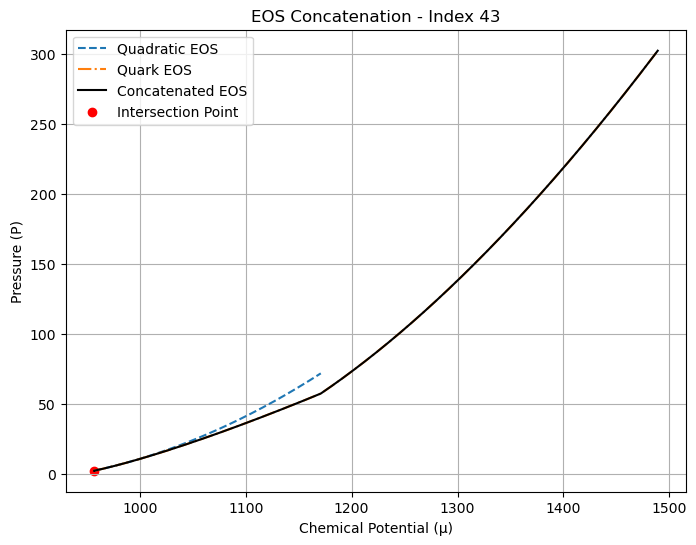

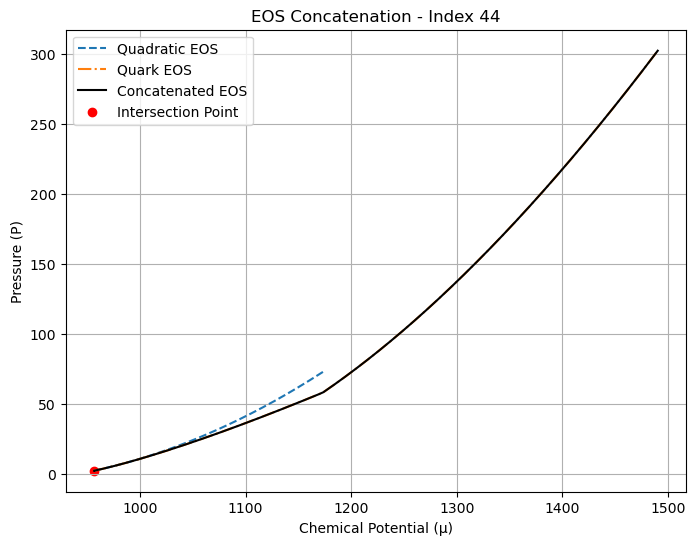

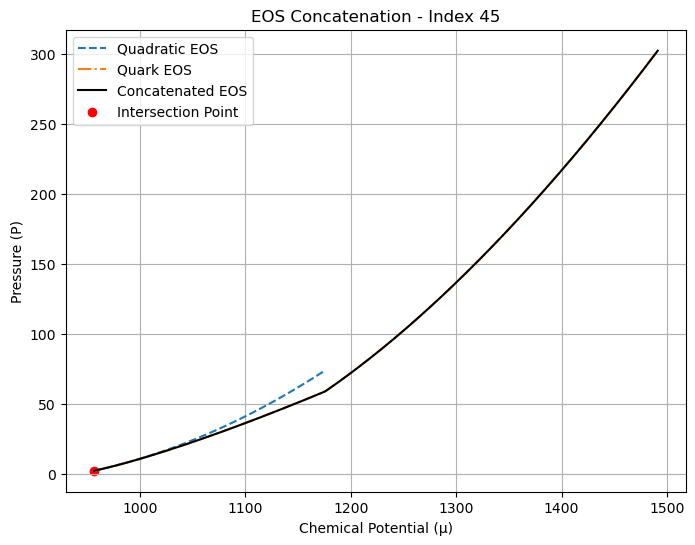

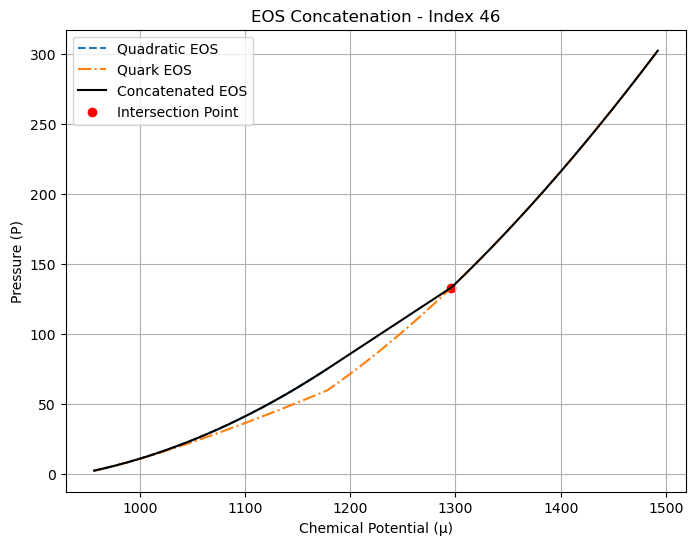

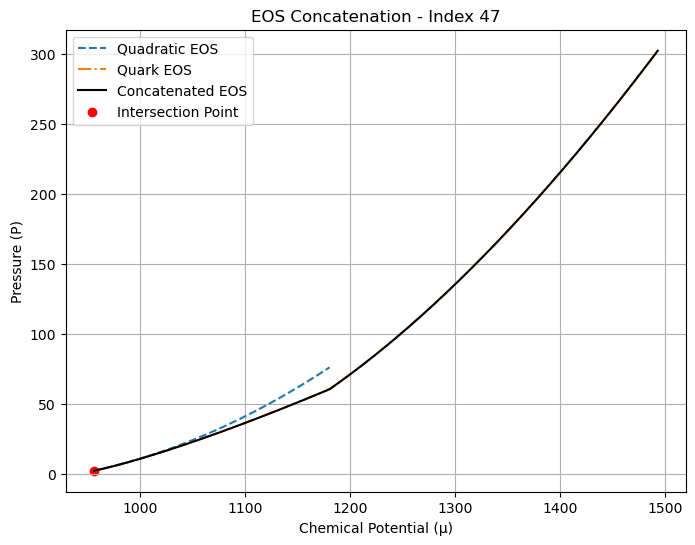

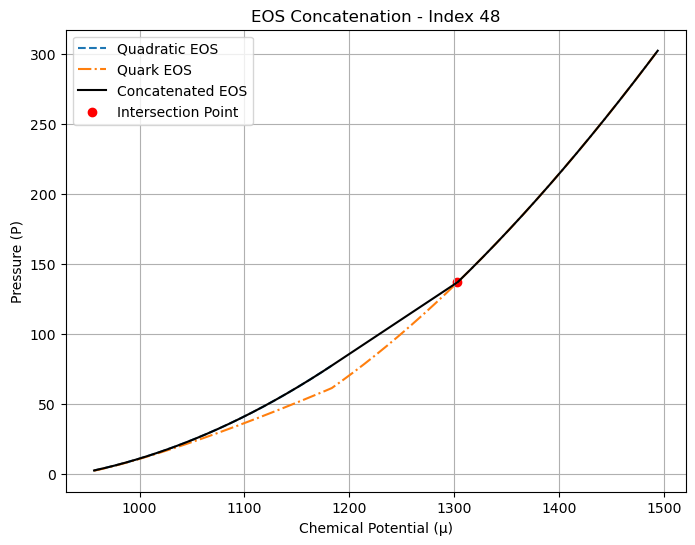

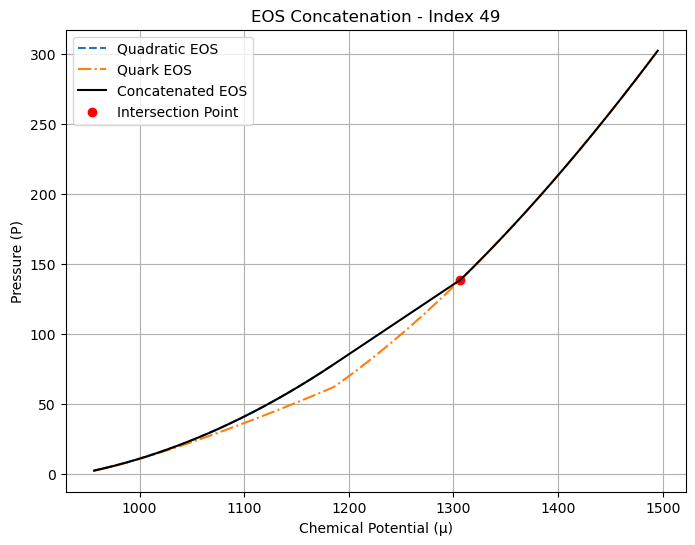

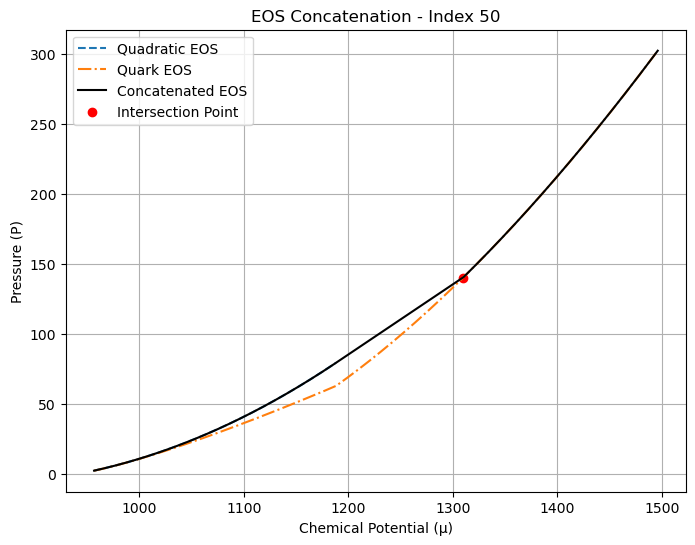

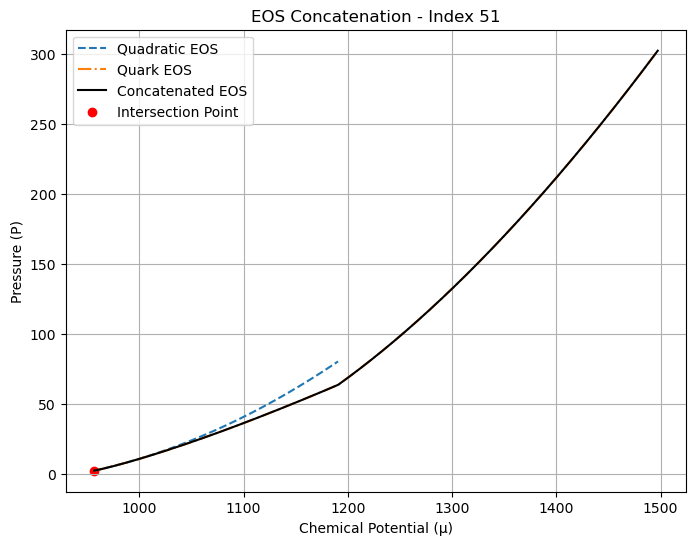

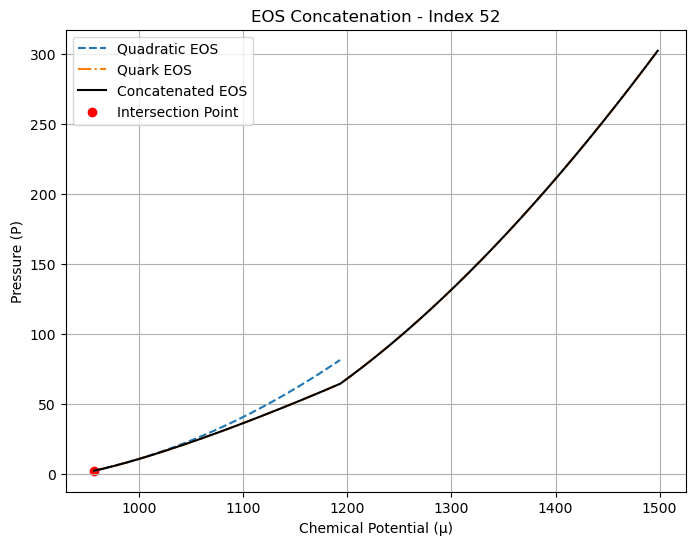

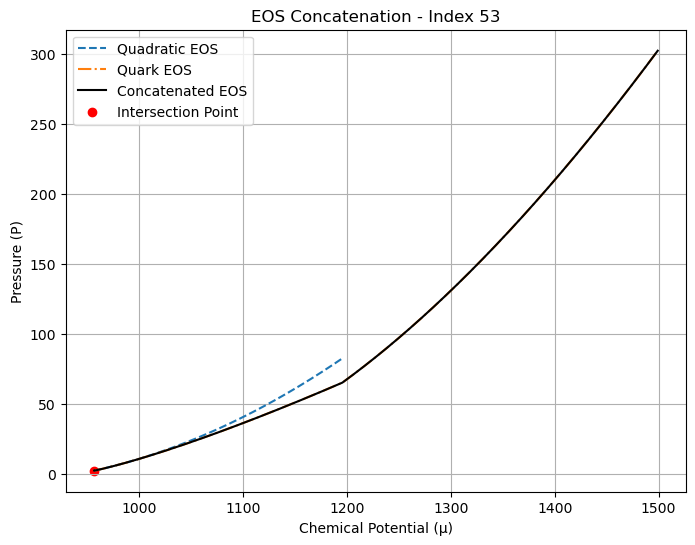

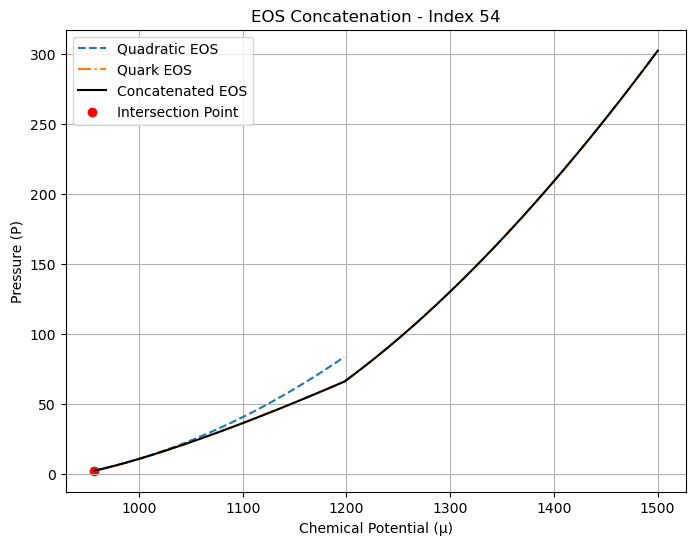

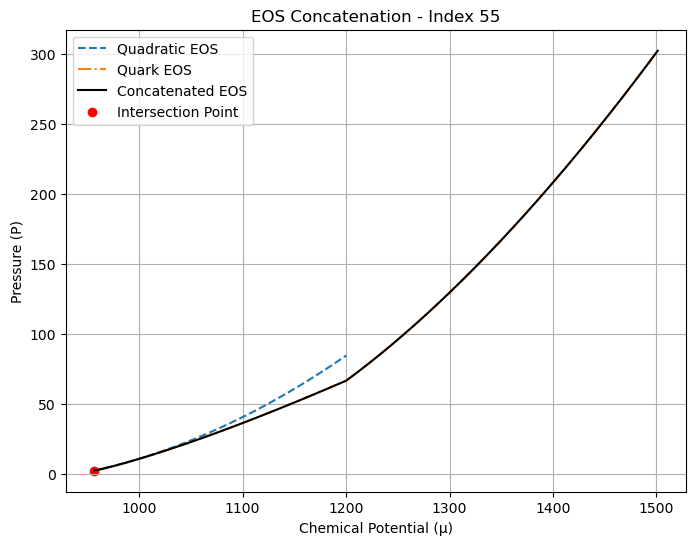

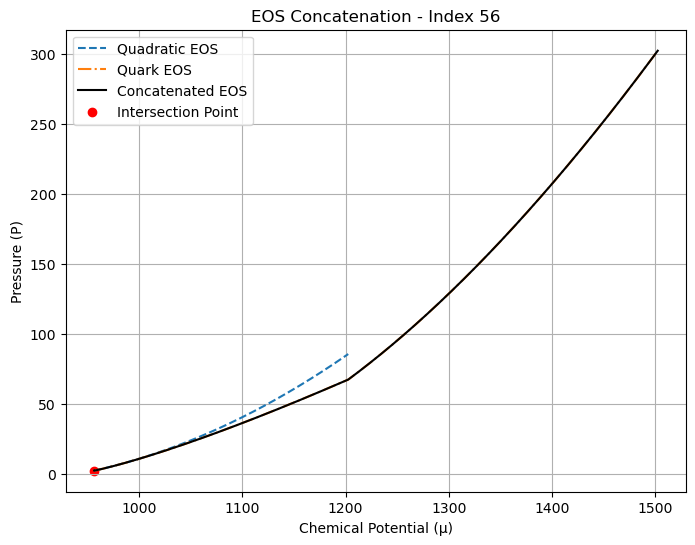

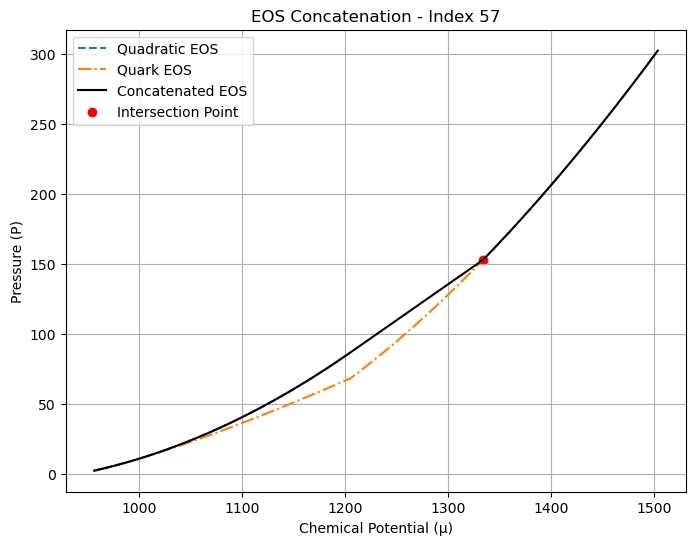

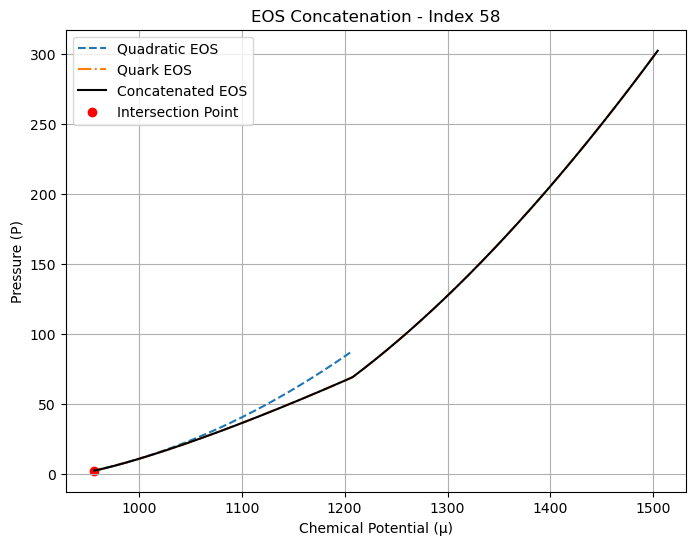

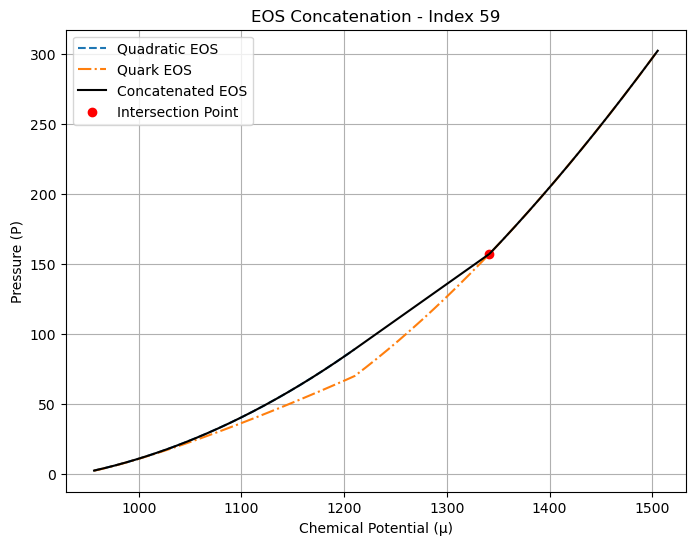

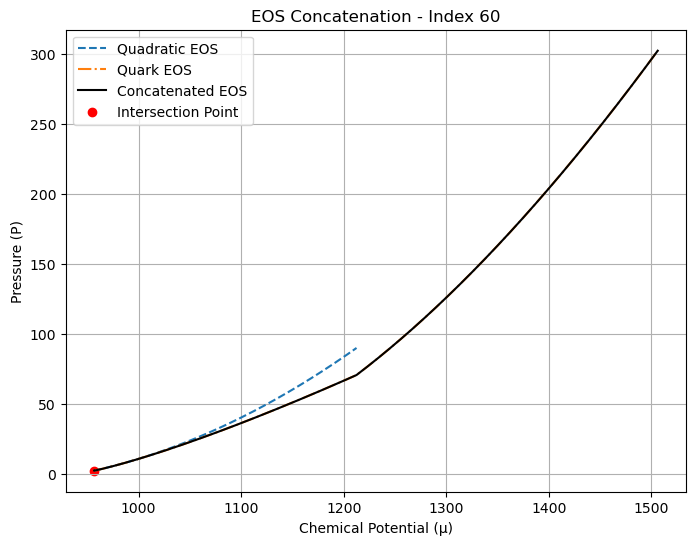

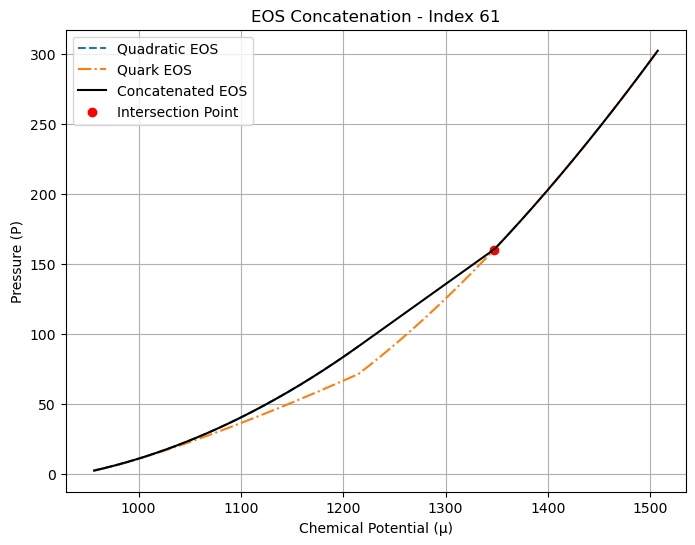

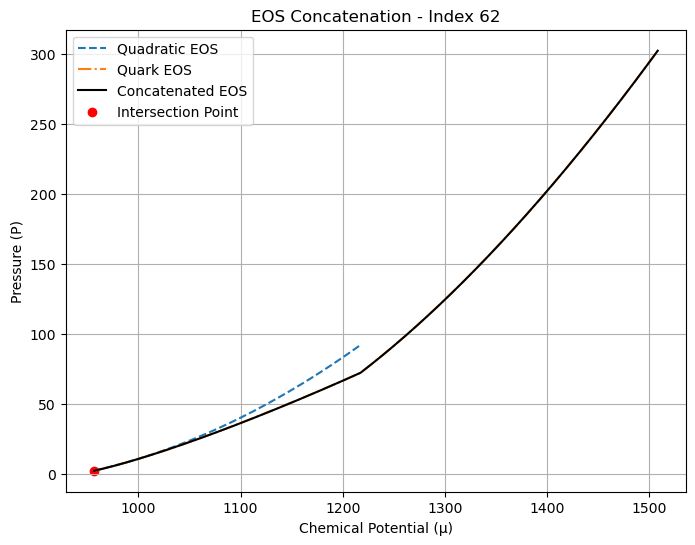

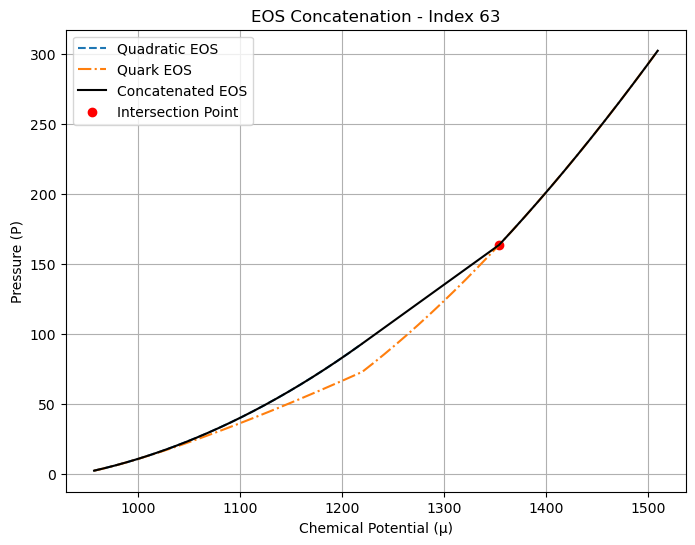

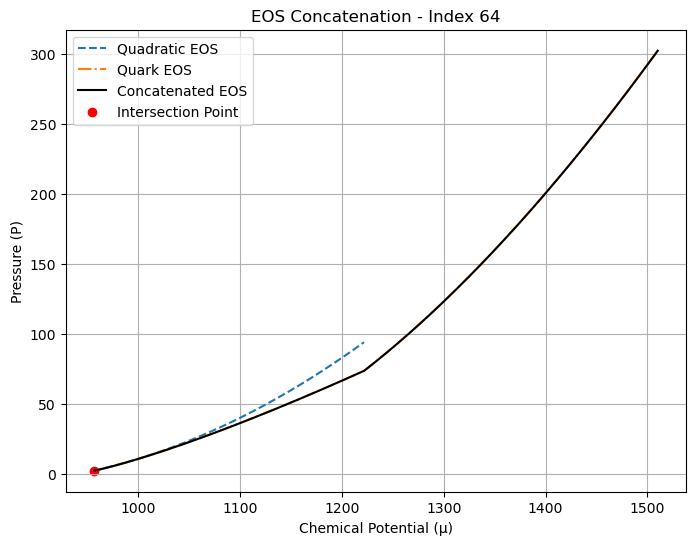

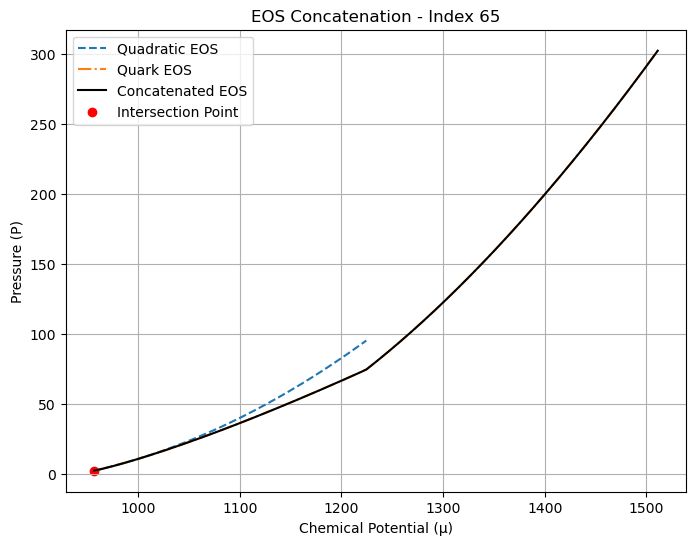

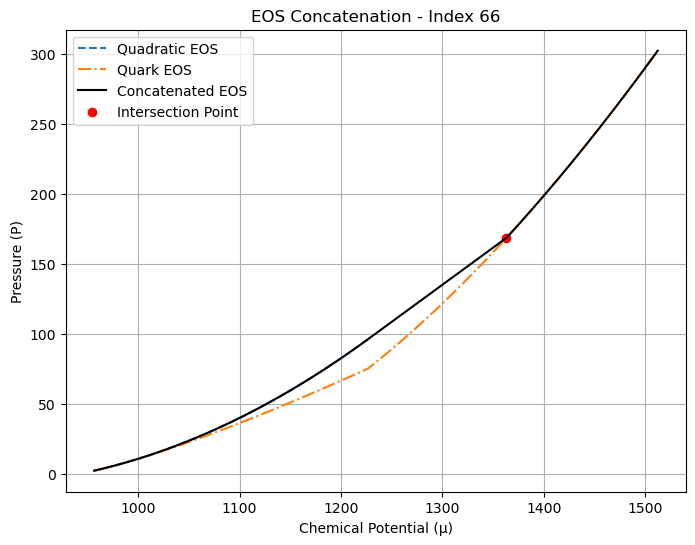

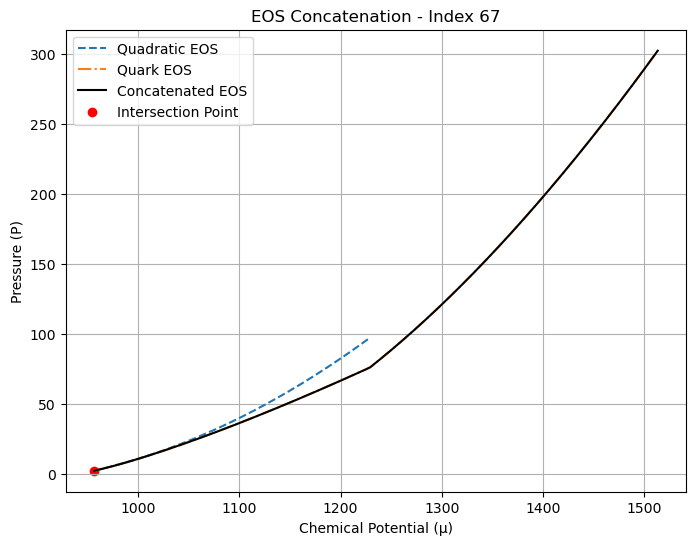

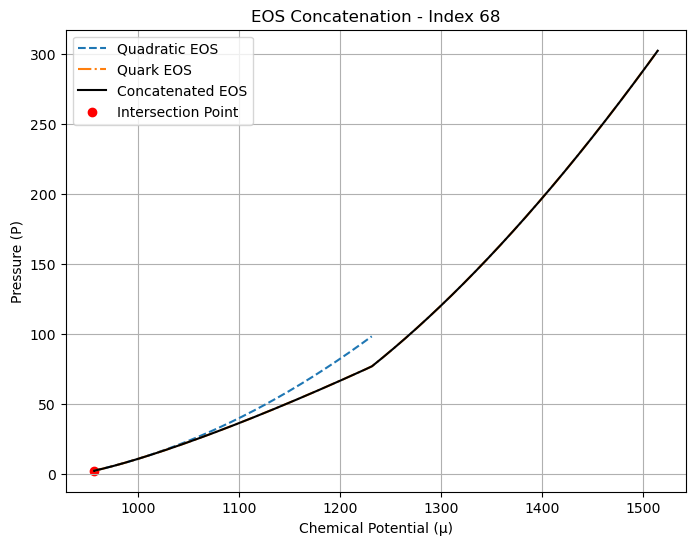

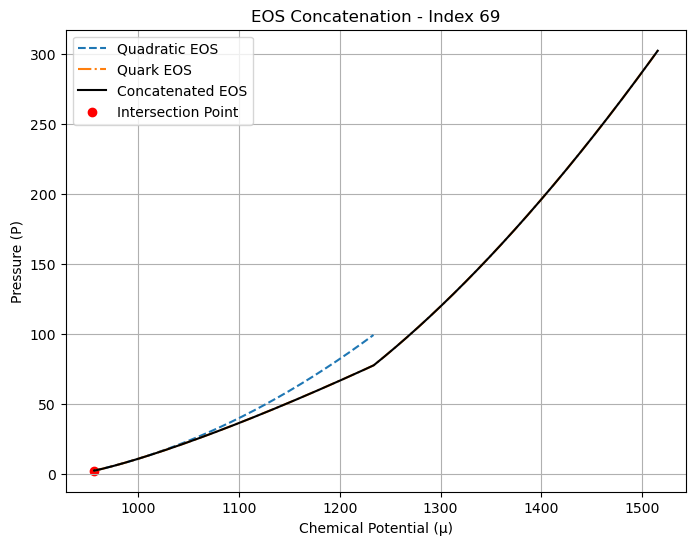

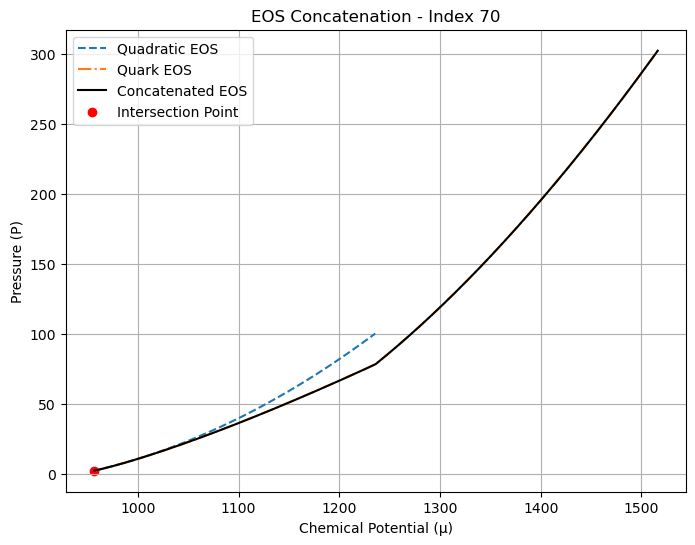

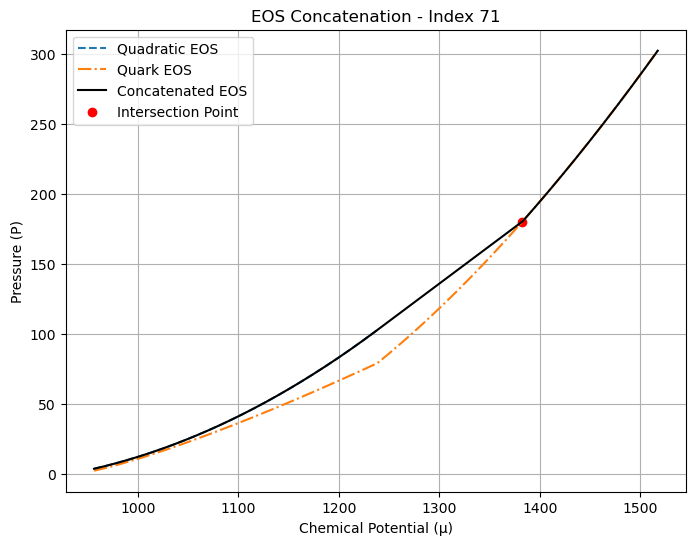

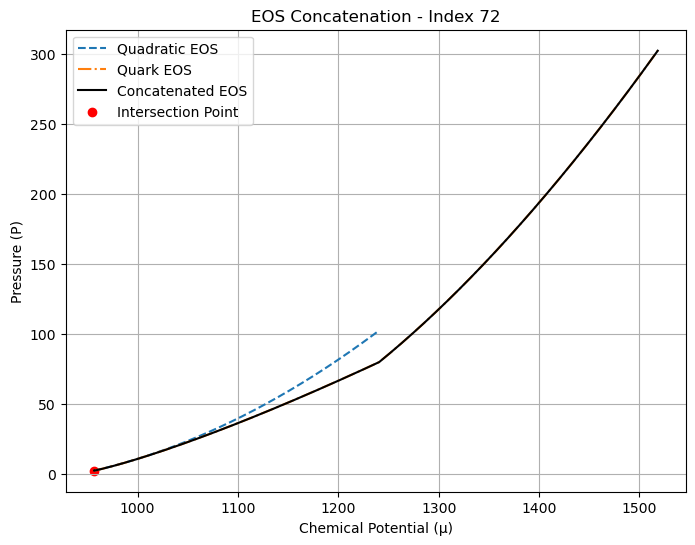

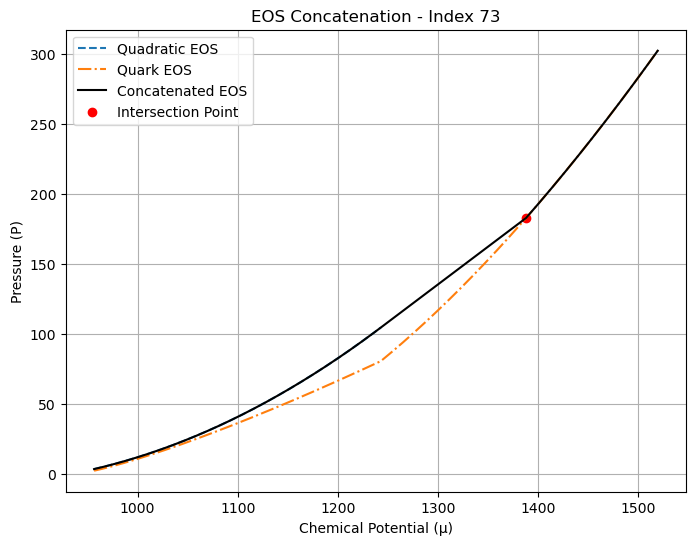

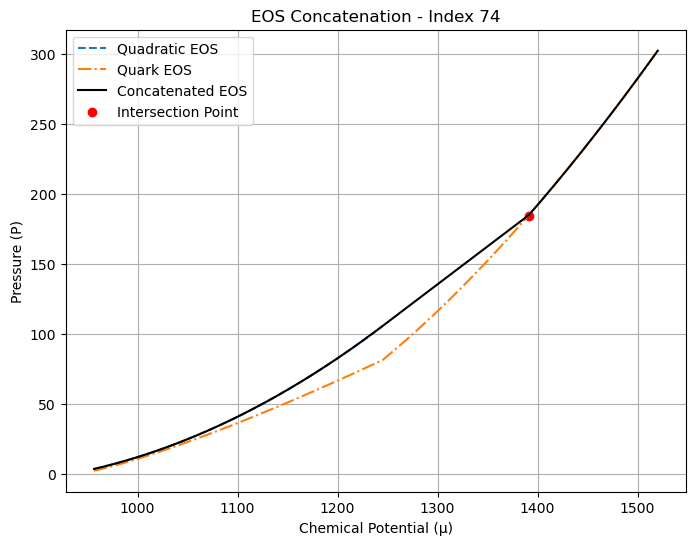

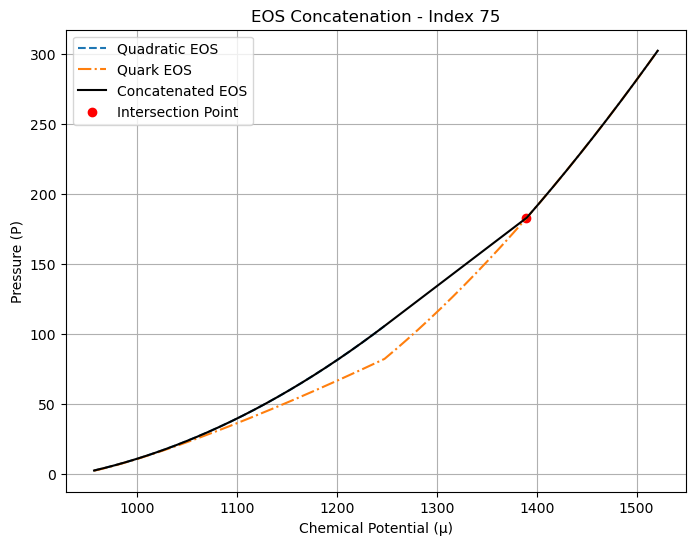

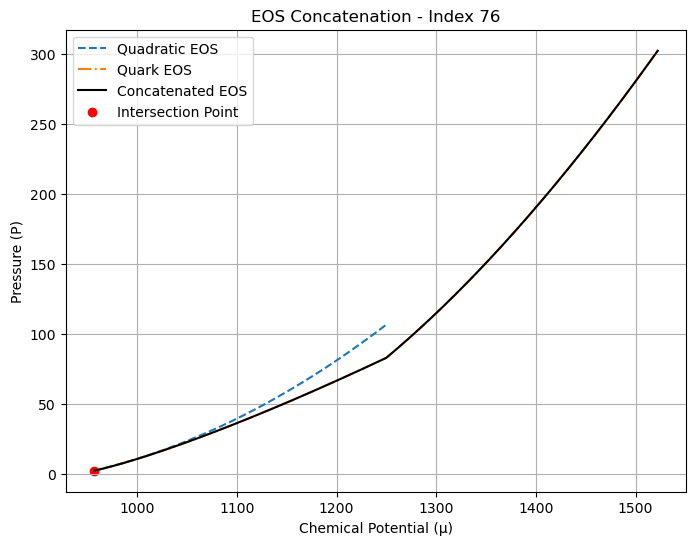

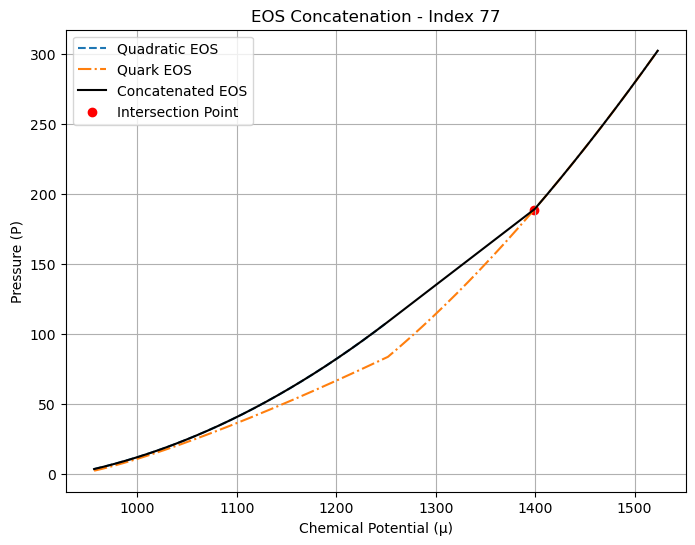

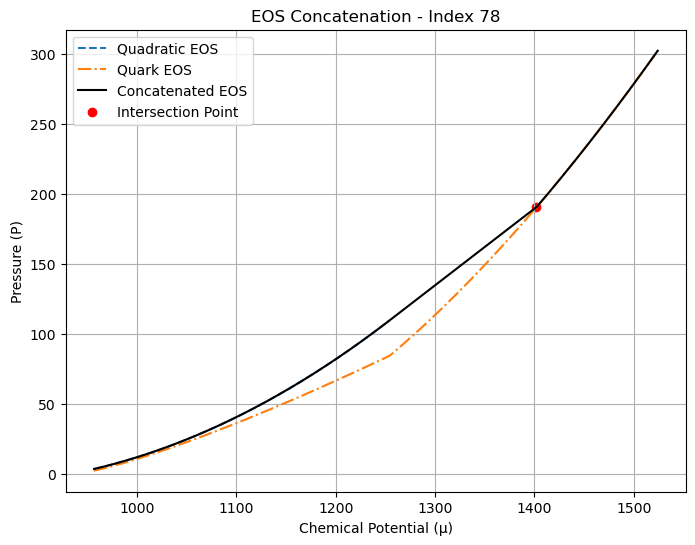

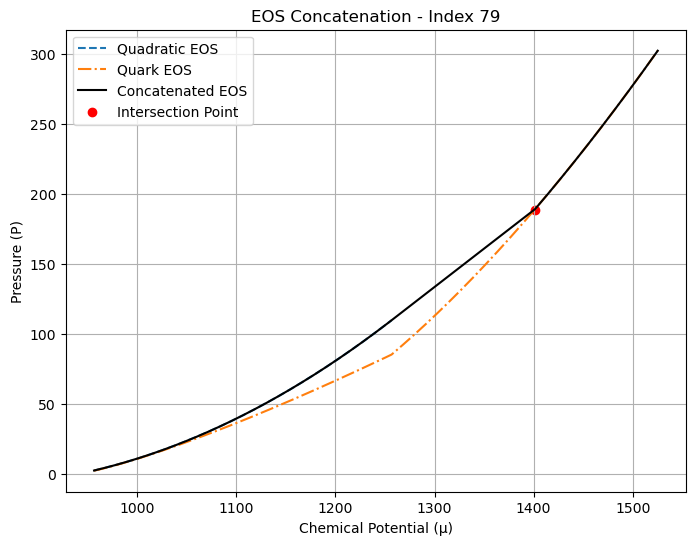

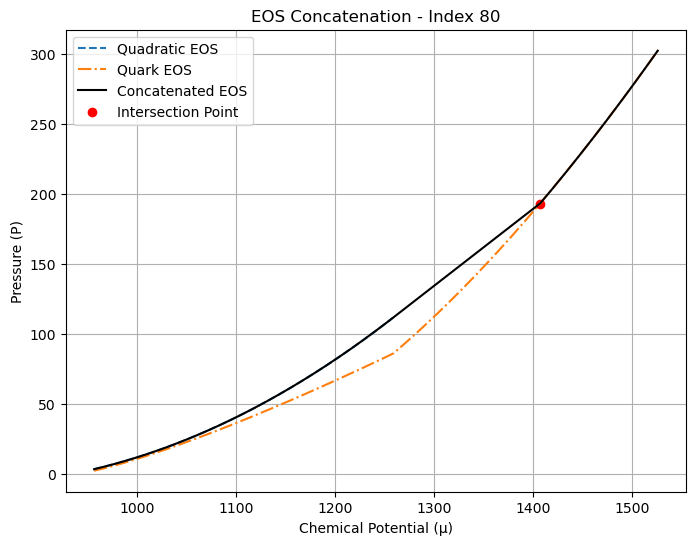

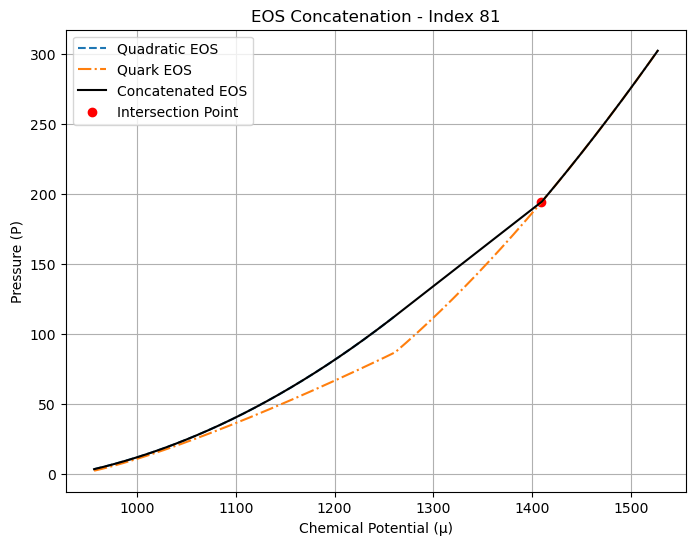

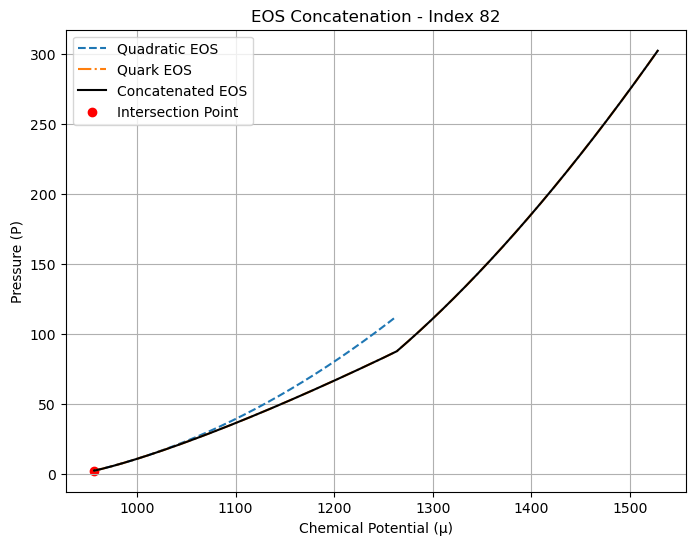

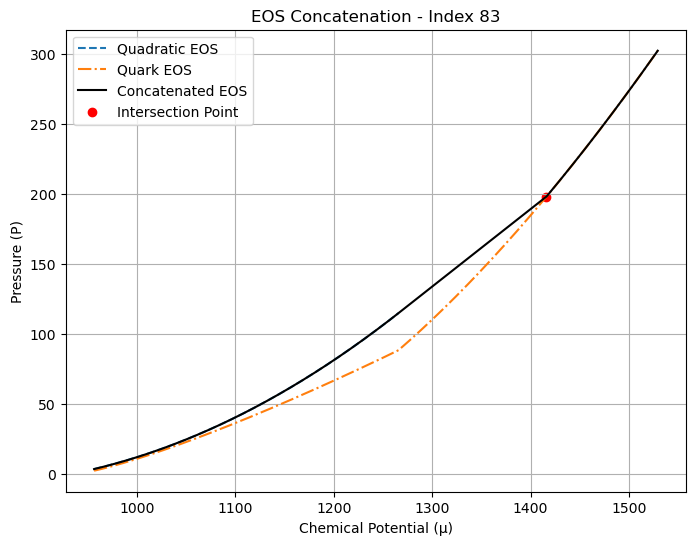

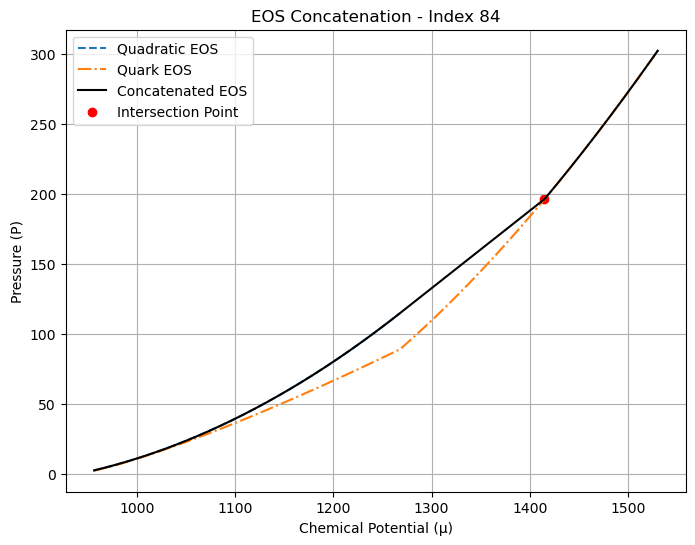

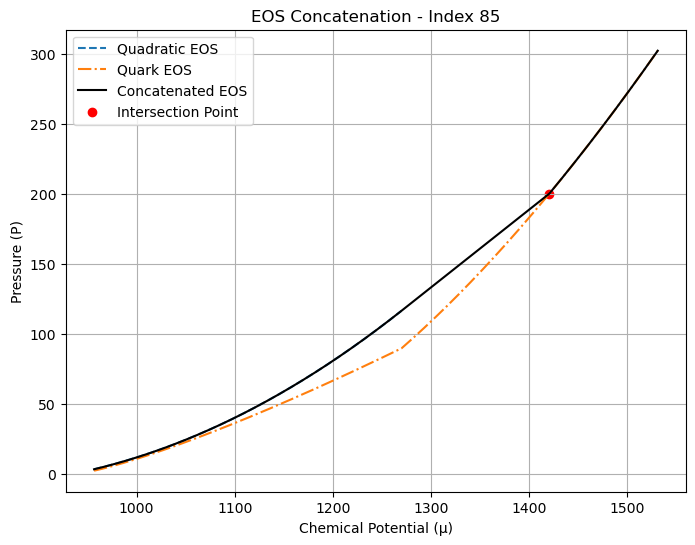

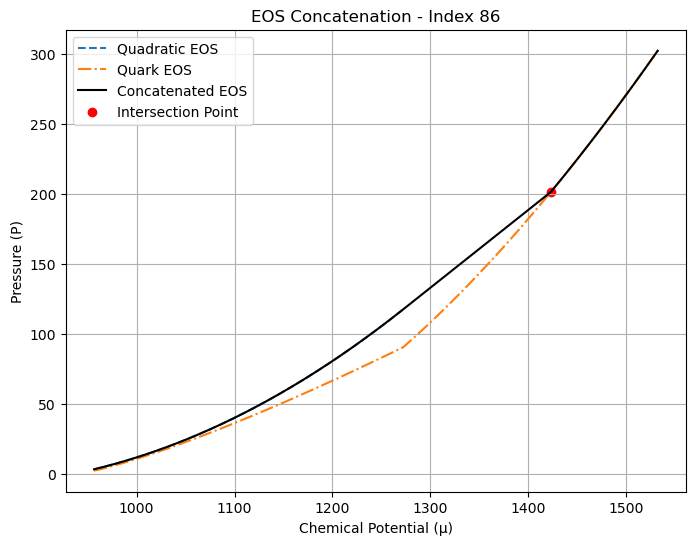

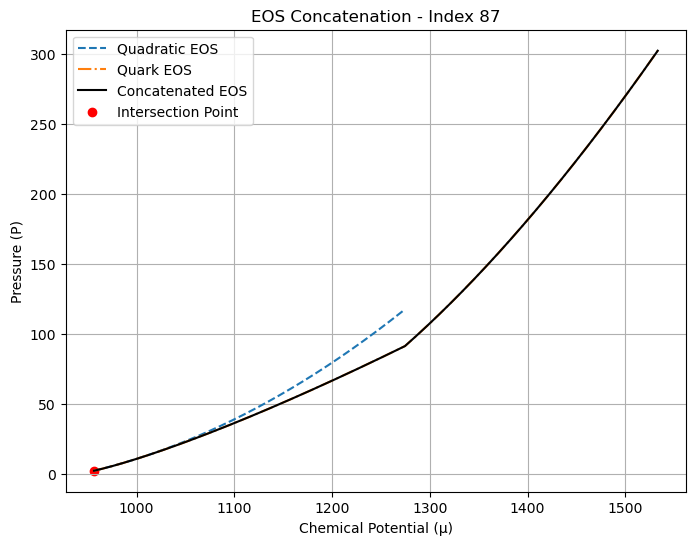

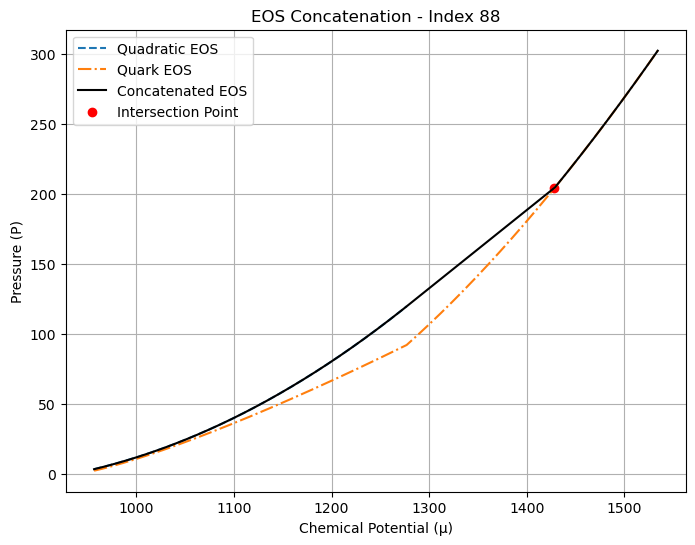

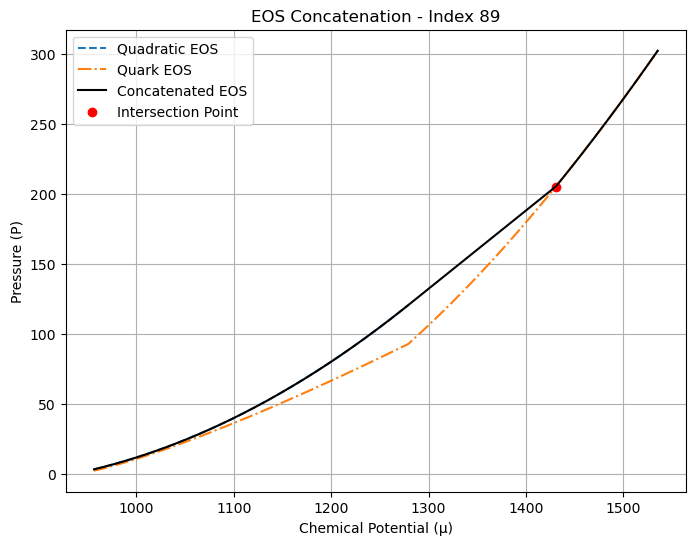

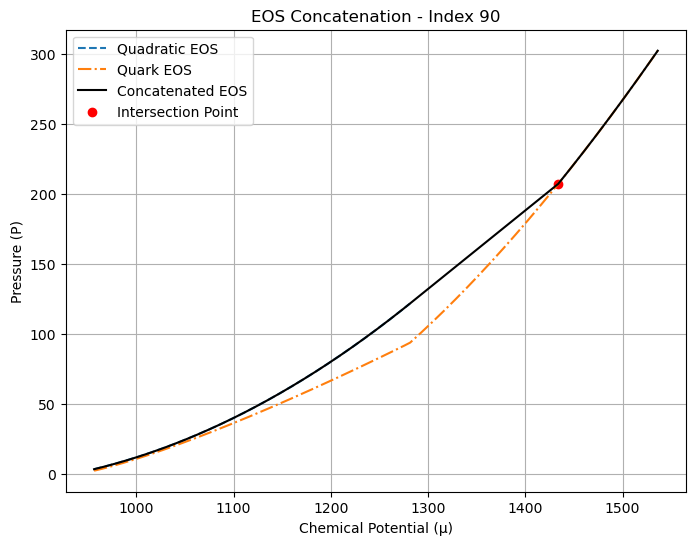

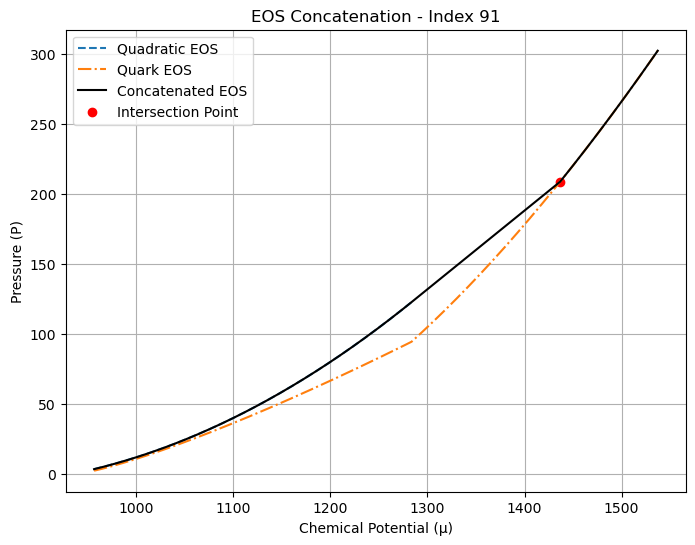

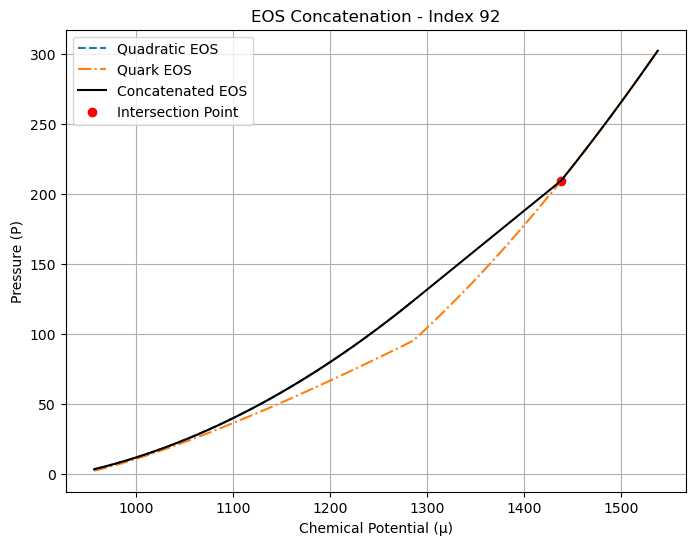

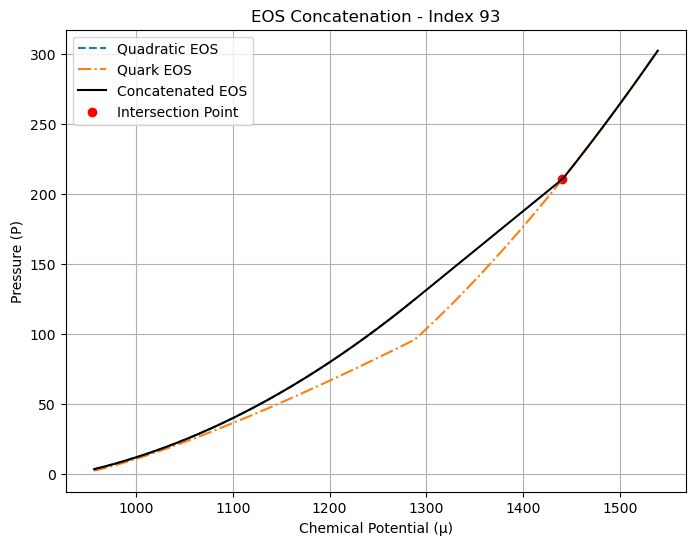

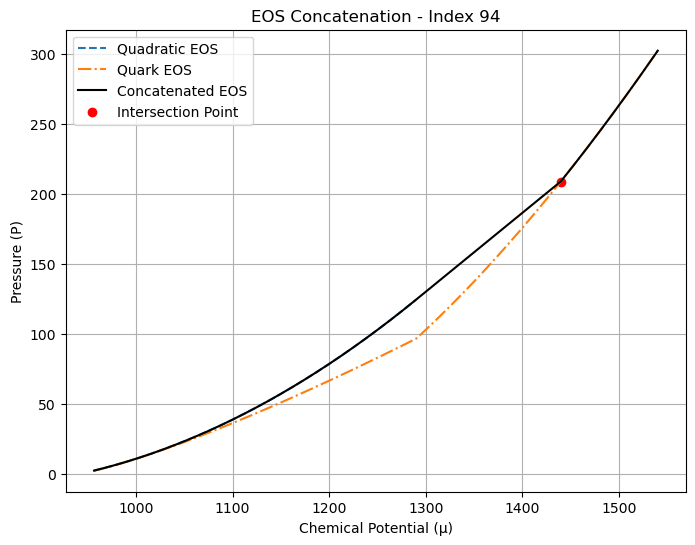

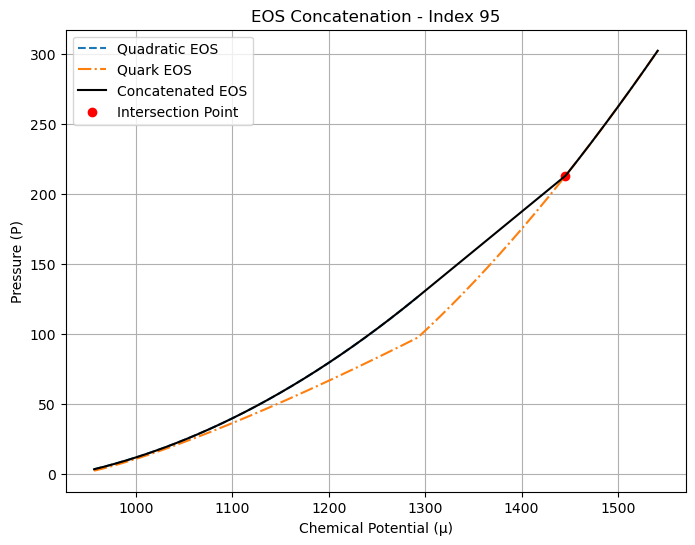

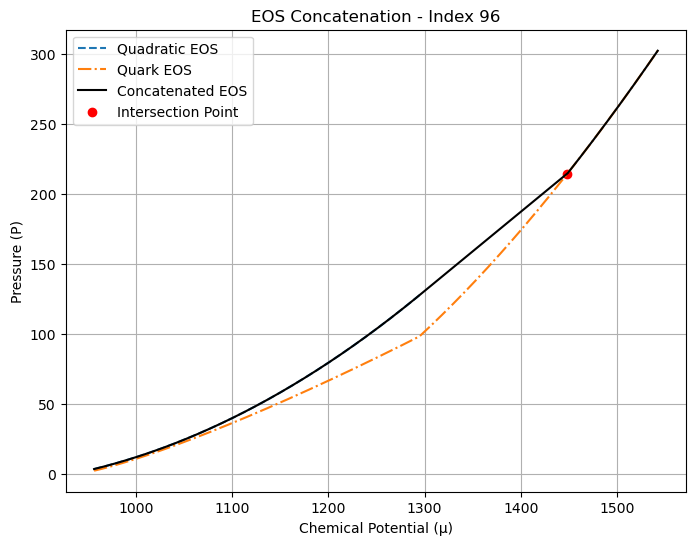

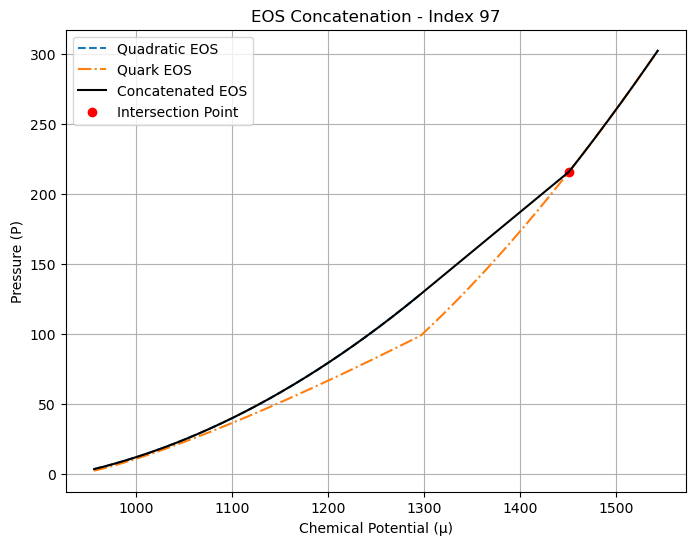

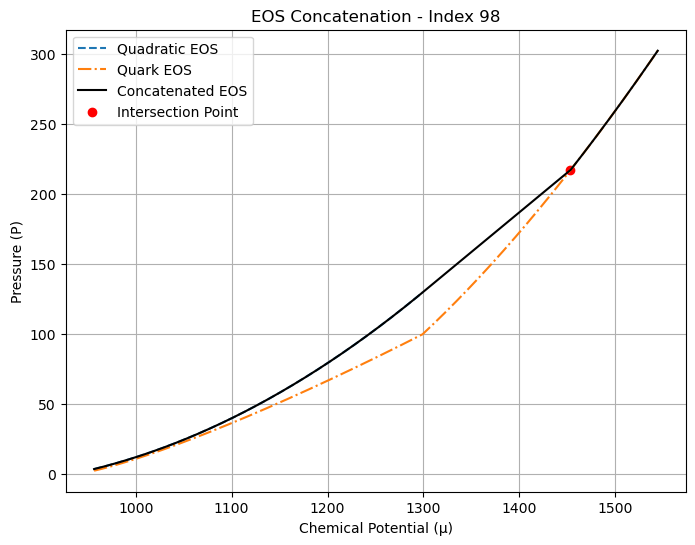

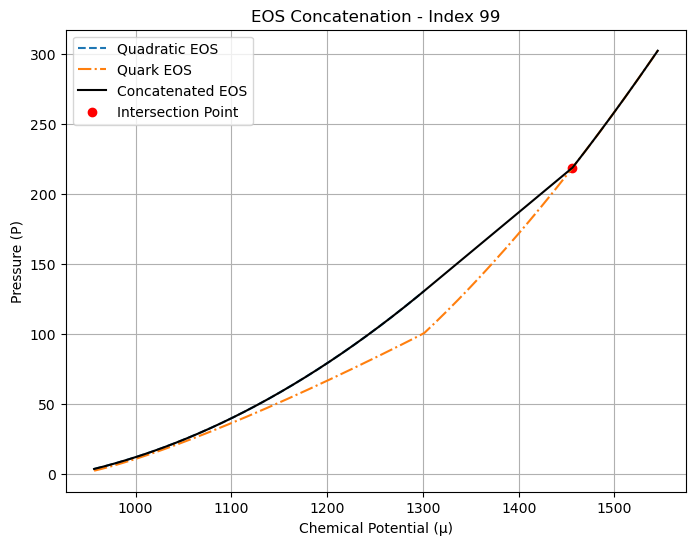

In [91]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# Lists to store concatenated EOS
mu_combined_list = []
P_combined_list = []

# Iterate through each index
for index in range(len(P_all)):

    # Skip invalid cases
    if P_all[index] == 0:
        continue

    # Retrieve first a_opt, b_opt, and pressure values
    a_opt = a_opt_first_values[index]
    b_opt = b_opt_first_values[index]
    P_crit = P_all[index]
    x2 = mu_crit[index]
    y2 = P_crit

    # Define quadratic EOS
    def quadratic(x):
        return a_opt * (x - x2)**2 + b_opt * (x - x2) + y2

    # Define mu range for quadratic EOS
    mu_quad = np.linspace(mu_total[index][0], x2, 1000)
    P_quad = quadratic(mu_quad)

    # Define Quark EOS
    mu_quark = mu_total[index]
    P_quark = p_total[index]

    # Interpolate both EOS over the full combined range
    mu_min_common = max(mu_quad.min(), mu_quark.min())
    mu_max_common = max(mu_quad.max(), mu_quark.max())
    mu_fine = np.linspace(mu_min_common, mu_max_common, 1000)

    P_quad_interp_func = interp1d(mu_quad, P_quad, kind="linear", fill_value="extrapolate")
    P_quark_interp_func = interp1d(mu_quark, P_quark, kind="linear", fill_value="extrapolate")

    P_quad_fine = P_quad_interp_func(mu_fine)
    P_quark_fine = P_quark_interp_func(mu_fine)

    # Calculate the difference and find the intersection point
    diff = np.abs(P_quad_fine - P_quark_fine)
    intersection_index = np.argmin(diff)
    mu_intersection = mu_fine[intersection_index]
    P_intersection = P_quad_fine[intersection_index]

    # Separate quadratic EOS up to the intersection
    mu_quad_truncated = mu_quad[mu_quad <= mu_intersection]
    P_quad_truncated = P_quad[mu_quad <= mu_intersection]

    # Separate quark EOS from the intersection point onward
    mu_quark_truncated = mu_quark[mu_quark >= mu_intersection]
    P_quark_truncated = P_quark[mu_quark >= mu_intersection]

    # Concatenate quadratic and quark EOS
    mu_combined = np.concatenate((mu_quad_truncated, mu_quark_truncated))
    P_combined = np.concatenate((P_quad_truncated, P_quark_truncated))

    # Save concatenated EOS
    mu_combined_list.append(mu_combined)
    P_combined_list.append(P_combined)

    # Plot individual EOS and concatenated EOS
    plt.figure(figsize=(8, 6))
    plt.plot(mu_quad, P_quad, label="Quadratic EOS", linestyle="--")
    plt.plot(mu_quark, P_quark, label="Quark EOS", linestyle="-.")
    plt.plot(mu_combined, P_combined, label="Concatenated EOS", color="black")
    plt.scatter(mu_intersection, P_intersection, color="red", label="Intersection Point")
    plt.xlabel("Chemical Potential (µ)")
    plt.ylabel("Pressure (P)")
    plt.title(f"EOS Concatenation - Index {index}")
    plt.legend()
    plt.grid()
    plt.show()

In [90]:
import numpy as np

# Lists to store number density and energy density for all concatenated EOS
n_combined_list = []
e_combined_list = []

# Iterate through each index
for index in range(len(P_combined_list)):

    # Get the combined chemical potential and pressure
    mu_combined = mu_combined_list[index]
    P_combined = P_combined_list[index]

    # Calculate the number density n (gradient of pressure with respect to mu)
    n_combined = np.gradient(P_combined, mu_combined)

    # Calculate the energy density e using the formula e = n * mu - P
    e_combined = n_combined * mu_combined - P_combined

    # Save the calculated values
    n_combined_list.append(n_combined)
    e_combined_list.append(e_combined)

In [ ]:
p_arr=Mev_fm3_to_GU*P_arr
E_arr=Mev_fm3_to_GU*e_arr

R =[]
M =[]
Com = []
Love = []

cden_arr = np.logspace(np.log10((min(E_arr)*1.1)),np.log10((max(E_arr)*0.99)),80)
radius,mass,comp,love_number=TOV_module(cden_arr,p_arr,E_arr,min(p_arr)*1.1,to_print=True,love=True)

In [94]:
import numpy as np

# Constants for unit conversion
Mev_fm3_to_GU = 1.0  # Replace with the appropriate conversion factor for pressure and energy density units

# Initialize lists to store results
R = []
M = []
Com = []
Love = []

# Assuming P_combined_list and e_combined_list are lists of lists with different lengths
# Loop over each set of pressure and energy density arrays
for index in range(len(P_combined_list)):

    # Extract the current pressure and energy density arrays for this index
    P_curr = np.array(P_combined_list[index])
    E_curr = np.array(e_combined_list[index])

    # Skip invalid cases
    if len(P_curr) == 0 or len(E_curr) == 0:
        continue

    # Convert pressure and energy density to the appropriate units
    P_curr_converted = Mev_fm3_to_GU * P_curr
    E_curr_converted = Mev_fm3_to_GU * E_curr

    # Prepare cden_arr for the TOV module
    cden_arr = np.logspace(np.log10(min(E_curr_converted) * 1.1), np.log10(max(E_curr_converted) * 0.99), 80)

    # Run the TOV module (assuming TOV_module is defined)
    radius, mass, comp, love_number = TOV_module(cden_arr, P_curr_converted, E_curr_converted, min(P_curr_converted) * 1.1, to_print=True, love=True)

    # Save the results for this EOS
    R.append(radius)
    M.append(mass)
    Com.append(comp)
    Love.append(love_number)

# After the loop, R, M, Com, and Love lists will contain results for each EOS
# You can now process or visualize these results as needed

PressureOutOfRangeError: Pressure is out of range.

In [95]:
import numpy as np

# Constants for unit conversion
Mev_fm3_to_GU = 1.0  # Replace with the appropriate conversion factor for pressure and energy density units

# Initialize lists to store results
R = []
M = []
Com = []
Love = []

# Get first and last EOS
first_EOS = P_combined_list[0], e_combined_list[0]  # First EOS
last_EOS = P_combined_list[-1], e_combined_list[-1]  # Last EOS

# Process first EOS
P_curr_first = np.array(first_EOS[0])
E_curr_first = np.array(first_EOS[1])

# Convert pressure and energy density to the appropriate units
P_curr_converted_first = Mev_fm3_to_GU * P_curr_first
E_curr_converted_first = Mev_fm3_to_GU * E_curr_first

# Ensure the pressures are within the valid range for the TOV module
min_P_first = min(P_curr_converted_first)
max_P_first = max(P_curr_converted_first)

if min_P_first < 1e-15:  # Set a lower limit to avoid zero or negative pressures
    P_curr_converted_first = P_curr_converted_first[P_curr_converted_first > 1e-15]

if max_P_first > 1e5:  # Set an upper limit to avoid excessively large pressures
    P_curr_converted_first = P_curr_converted_first[P_curr_converted_first < 1e5]

# Prepare cden_arr for the TOV module for the first EOS
cden_arr_first = np.logspace(np.log10(min(E_curr_converted_first) * 1.1), np.log10(max(E_curr_converted_first) * 0.99), 80)

# Run the TOV module for the first EOS
try:
    radius_first, mass_first, comp_first, love_number_first = TOV_module(cden_arr_first, P_curr_converted_first, E_curr_converted_first, min(P_curr_converted_first) * 1.1, to_print=True, love=True)
    # Save the results for the first EOS
    R.append(radius_first)
    M.append(mass_first)
    Com.append(comp_first)
    Love.append(love_number_first)
except PressureOutOfRangeError as e:
    print(f"Warning: {e} for the first EOS, skipping this EOS.")

# Process last EOS
P_curr_last = np.array(last_EOS[0])
E_curr_last = np.array(last_EOS[1])

# Convert pressure and energy density to the appropriate units
P_curr_converted_last = Mev_fm3_to_GU * P_curr_last
E_curr_converted_last = Mev_fm3_to_GU * E_curr_last

# Ensure the pressures are within the valid range for the TOV module
min_P_last = min(P_curr_converted_last)
max_P_last = max(P_curr_converted_last)

if min_P_last < 1e-15:  # Set a lower limit to avoid zero or negative pressures
    P_curr_converted_last = P_curr_converted_last[P_curr_converted_last > 1e-15]

if max_P_last > 1e5:  # Set an upper limit to avoid excessively large pressures
    P_curr_converted_last = P_curr_converted_last[P_curr_converted_last < 1e5]

# Prepare cden_arr for the TOV module for the last EOS
cden_arr_last = np.logspace(np.log10(min(E_curr_converted_last) * 1.1), np.log10(max(E_curr_converted_last) * 0.99), 80)

# Run the TOV module for the last EOS
try:
    radius_last, mass_last, comp_last, love_number_last = TOV_module(cden_arr_last, P_curr_converted_last, E_curr_converted_last, min(P_curr_converted_last) * 1.1, to_print=True, love=True)
    # Save the results for the last EOS
    R.append(radius_last)
    M.append(mass_last)
    Com.append(comp_last)
    Love.append(love_number_last)
except PressureOutOfRangeError as e:
    print(f"Warning: {e} for the last EOS, skipping this EOS.")

# After the loop, R, M, Com, and Love lists will contain results for the first and last EOS
print("First EOS Results:")
print(f"Radius: {R[0]}")
print(f"Mass: {M[0]}")
print(f"Compactness: {Com[0]}")
print(f"Love Number: {Love[0]}")

print("\nLast EOS Results:")
print(f"Radius: {R[1]}")
print(f"Mass: {M[1]}")
print(f"Compactness: {Com[1]}")
print(f"Love Number: {Love[1]}")

First EOS Results:


IndexError: list index out of range